# EAGLE workflow

Prepare datasets and networks, train the three source models, and run the six evaluations. This notebook is saved unexecuted. Use the EAGLE Python kernel described in `Documentation.md`.

Start Ryu and Mininet in external terminals with the selected network. Restart both manually whenever changing topology, starting Ryu first. Collection for each topology is performed in a separate notebook invocation of the collection cell.


In [1]:
import json
import shlex
import subprocess
from pathlib import Path

from IPython.display import SVG, Image, display

ROOT = Path.cwd().resolve()
assert (ROOT / "config.py").exists(), "Open the notebook from the repository root"
PYTHON = ROOT / "model/.venv/bin/python"
SOURCE_HOSTS = 9
V4_HOSTS = 30
SEED = 42
MIN_DECISIONS = 20
SKIP_PCAPS = False
SKIP_V4_TRAIN = True
DECISION_SECONDS = 5
EPISODES = 15
PRETRAIN_EPISODES = 5
POSTTRAIN_EPISODES = 5
EVAL_EPISODES = 5
REPETITIONS = 1
SOURCE_MODELS = ["dc_t0", "dc_pcaps", "dc_full"]
MODELS = SOURCE_MODELS.copy()
SOURCE_DATA = ROOT / f"datasets/{SOURCE_HOSTS}_hosts"
V4_DATA = ROOT / f"datasets/{V4_HOSTS}_hosts"


def run(module, *arguments):
    command = [str(PYTHON), "-m", module, *map(str, arguments)]
    print(shlex.join(command), flush=True)
    process = subprocess.Popen(
        command,
        cwd=ROOT,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
        bufsize=1,
    )
    try:
        for line in process.stdout:
            print(line, end="", flush=True)
        status = process.wait()
    except BaseException:
        process.terminate()
        try:
            process.wait(timeout=10)
        except subprocess.TimeoutExpired:
            process.kill()
            process.wait()
        raise
    finally:
        process.stdout.close()
    if status:
        raise subprocess.CalledProcessError(status, command)


def show_png(path):
    display(Image(filename=str(ROOT / path)))


def show_network(name):
    display(SVG(filename=str(ROOT / f"networks/{name}.svg")))

## Inspect source captures

The inputs are `5gb-tcp-connection.pcap.gz` and Megalodon's Content Server capture saved as `megalodon.pcapng` in the repository root. These cells analyze complete captures and display their throughput histories.


In [ ]:
run("data_preparation.analyze_trace")
run("data_preparation.analyze_trace", "--mg")
show_png("datasets/analyses/dc/traffic_1s.png")
show_png("datasets/analyses/mg/traffic_1s.png")

## Prepare source and larger-host datasets

Each command creates a fresh host-count directory. Move existing output aside before regenerating it. Pooling uses every available split window before repeating. `min_decisions=20` requires at least 100 seconds per direction after scaling at five seconds per decision. Source windows are repeated only when their scaled duration falls short of this minimum. Megalodon synthetic traffic also supplies test condition T2.

`Config.TRAFFIC_SCALE_FACTOR` in `config.py` controls time stretching. `None` uses the host count. With nine hosts, 12 source windows produce 108 seconds and 21 complete five-second decisions, meeting a minimum of 20. Longer available sequences are retained. Synthetic traffic preserves each window's bytes over its longer delivery interval.

Set `SKIP_PCAPS=True` for synthetic-only generation without packet spooling. `SKIP_V4_TRAIN=True` generates only test datasets for the larger network. PCAP training and evaluation cells use captures from a full preparation run.


In [16]:
for hosts in (SOURCE_HOSTS, V4_HOSTS):
    options = []
    if SKIP_PCAPS:
        options.append("--skip-pcaps")
    if hosts == V4_HOSTS and SKIP_V4_TRAIN:
        options.append("--skip-train")
    run(
        "data_preparation",
        "default",
        "--hosts",
        hosts,
        "--min-decisions",
        MIN_DECISIONS,
        "--decision-seconds",
        DECISION_SECONDS,
        "--seed",
        SEED,
        *options,
    )

manifest_names = (
    ("dc_t0", "mg_t0") if SKIP_PCAPS else ("dc_t0", "dc_pcap", "mg_t0", "mg_pcap")
)
for name in manifest_names:
    manifest = json.loads((SOURCE_DATA / "test" / f"{name}.json").read_text())
    print(name, {key: manifest[key] for key in ("duration_seconds", "decisions")})


/home/olzhas/sdn/EAGLE-replica/model/.venv/bin/python -m data_preparation default --hosts 9 --min-decisions 20 --decision-seconds 5 --seed 42
/home/olzhas/sdn/EAGLE-replica/datasets/9_hosts
/home/olzhas/sdn/EAGLE-replica/model/.venv/bin/python -m data_preparation default --hosts 30 --min-decisions 20 --decision-seconds 5 --seed 42 --skip-train
/home/olzhas/sdn/EAGLE-replica/datasets/30_hosts
dc_t0 {'duration_seconds': 108, 'decisions': 21}
dc_pcap {'duration_seconds': 108, 'decisions': 21}
mg_t0 {'duration_seconds': 108, 'decisions': 21}
mg_pcap {'duration_seconds': 108, 'decisions': 21}


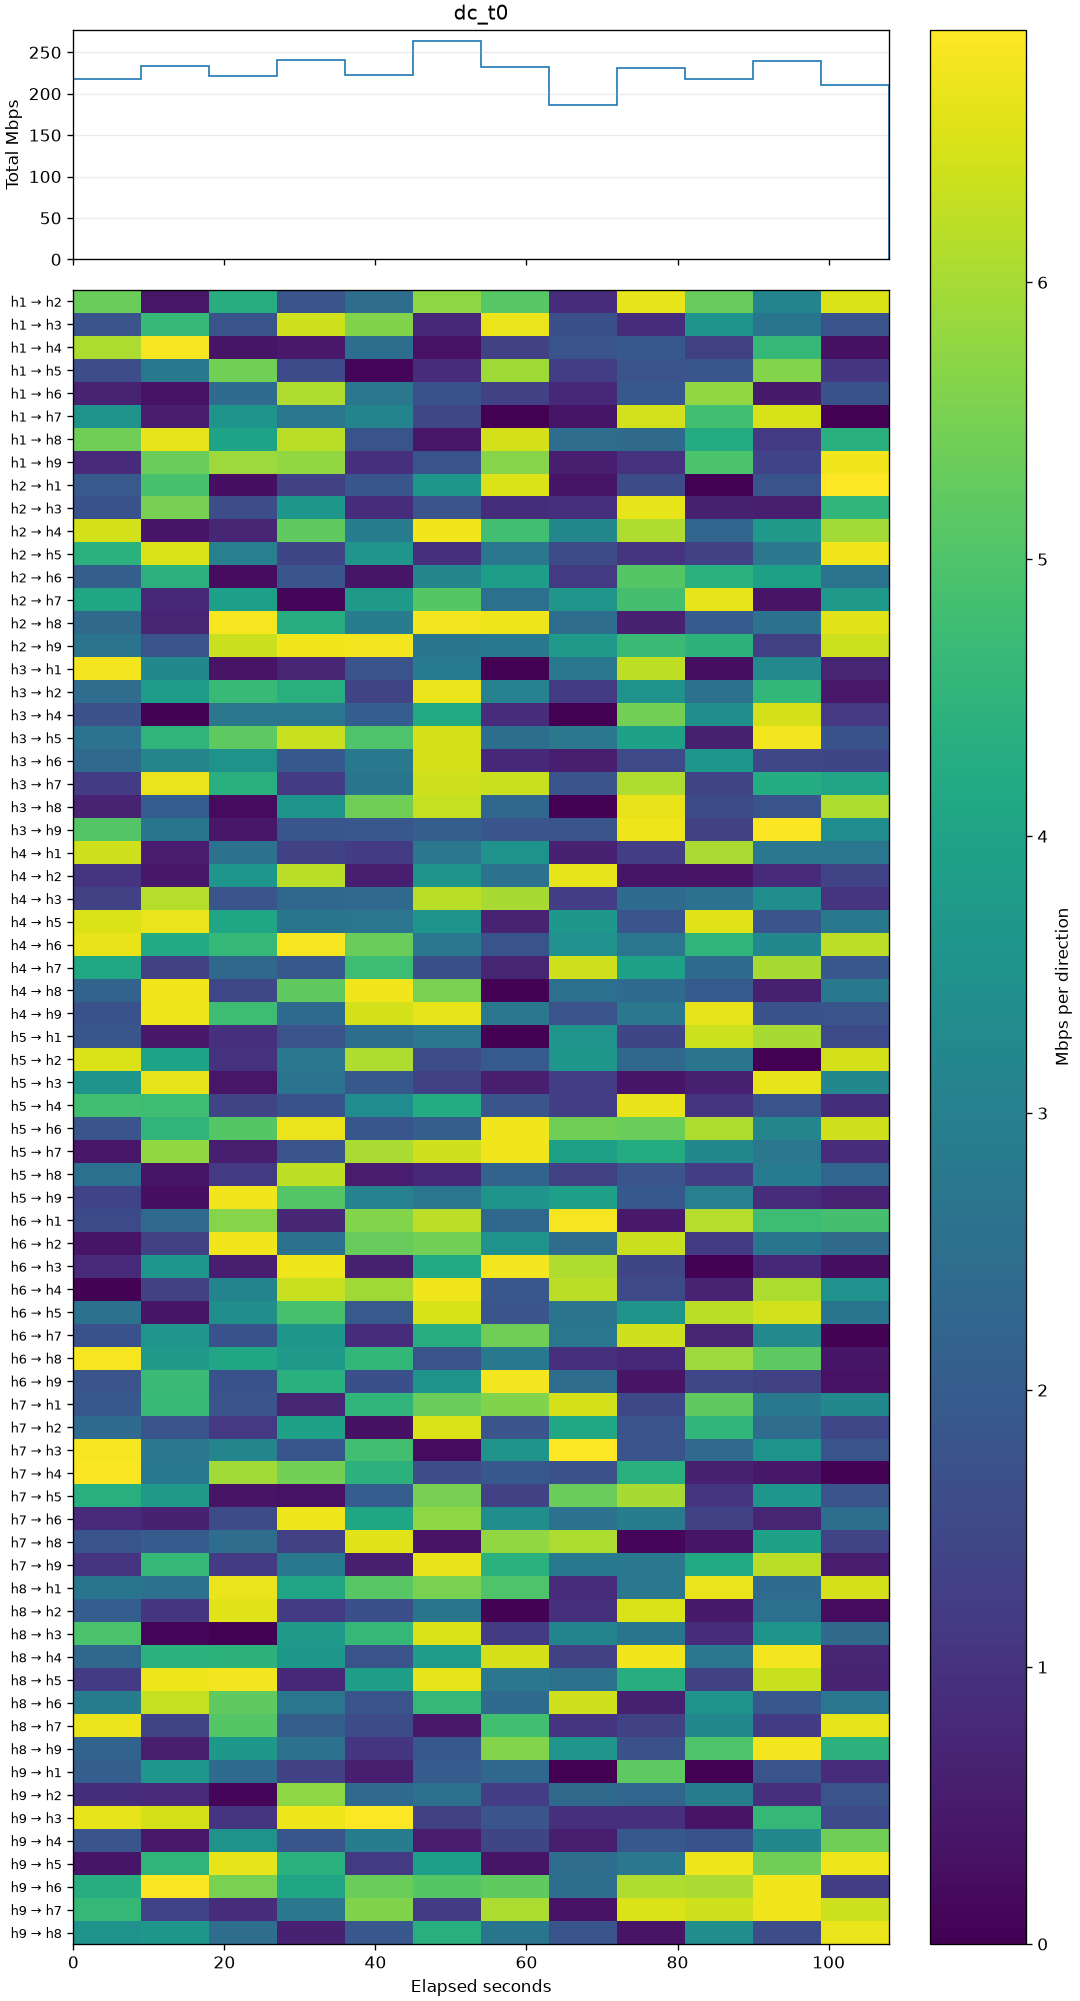

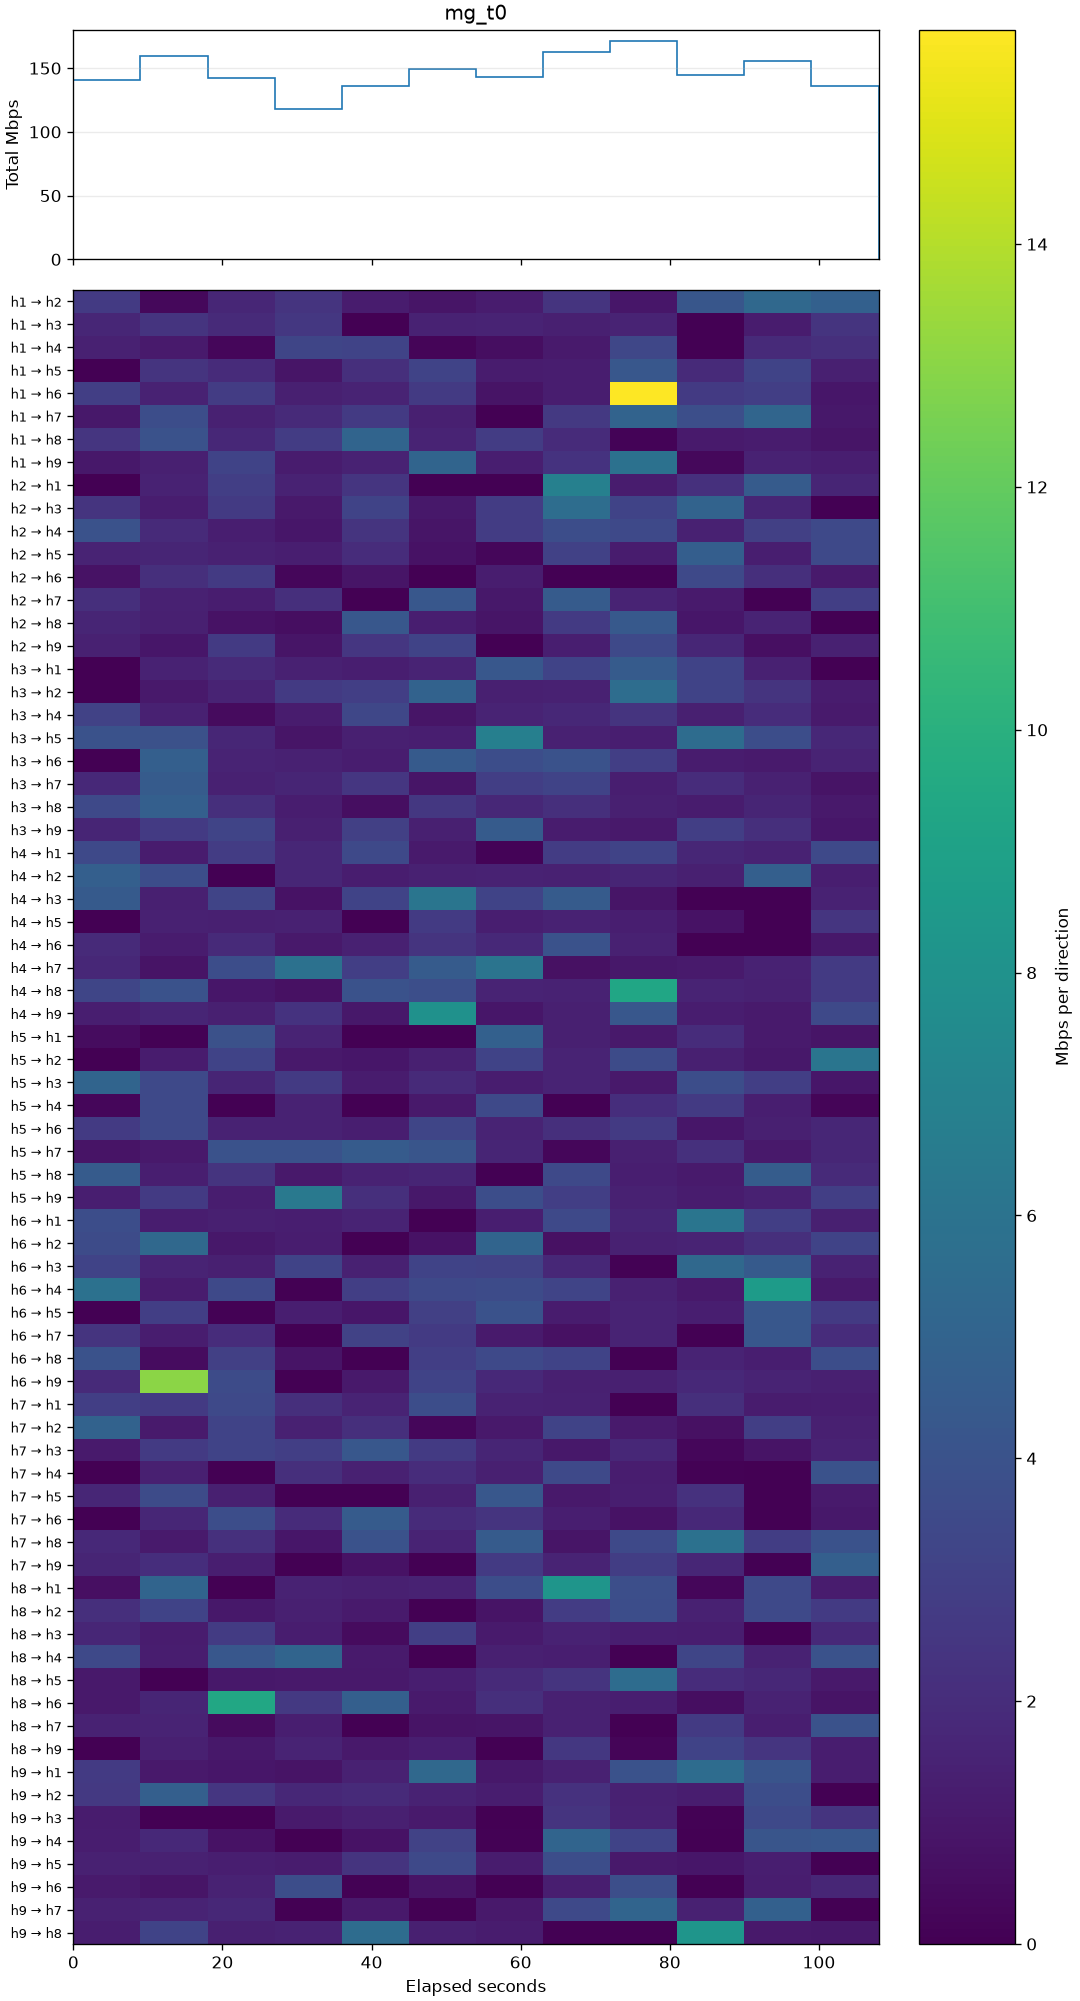

In [17]:
show_png(SOURCE_DATA / "test/dc_t0.png")
show_png(SOURCE_DATA / "test/mg_t0.png")


## Generate topology files

V0 preserves the source switch graph and takes host identities from the prepared dataset. V3 extends V0 to 16 switches and 22 inter-switch links. V1 and V2 use the random generator. V4 uses GtsCe with the larger-host dataset. Adjust the random topology inputs and V4 host count above for your experiment.


In [18]:
source_manifest = SOURCE_DATA / "train/dc_t0.json"
# run("network_preparation", "v0", "--dataset", source_manifest, "--seed", SEED)
# run("network_preparation", "v3", "--dataset", source_manifest, "--seed", SEED)
# run(
#     "network_preparation",
#     "random",
#     "--nodes",
#     13,
#     "--links",
#     16,
#     "--dataset",
#     source_manifest,
#     "--name",
#     "v1",
#     "--seed",
#     SEED,
# )
# run(
#     "network_preparation",
#     "random",
#     "--nodes",
#     13,
#     "--links",
#     18,
#     "--dataset",
#     source_manifest,
#     "--name",
#     "v2",
#     "--seed",
#     SEED,
# )
run(
    "network_preparation",
    "zoo",
    "--topo",
    "GtsCe",
    "--dataset",
    V4_DATA / "test/dc_t0.json",
    "--name",
    "v4",
    "--seed",
    SEED,
)

/home/olzhas/sdn/EAGLE-replica/model/.venv/bin/python -m network_preparation zoo --topo GtsCe --dataset /home/olzhas/sdn/EAGLE-replica/datasets/30_hosts/test/dc_t0.json --name v4 --seed 42
GtsCe  149 switches, 193 links
/home/olzhas/sdn/EAGLE-replica/networks/v4.json


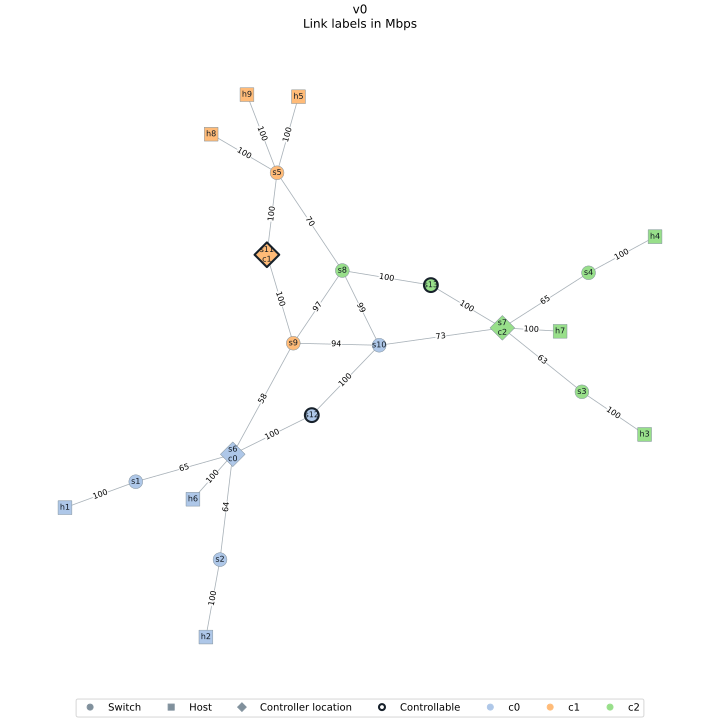

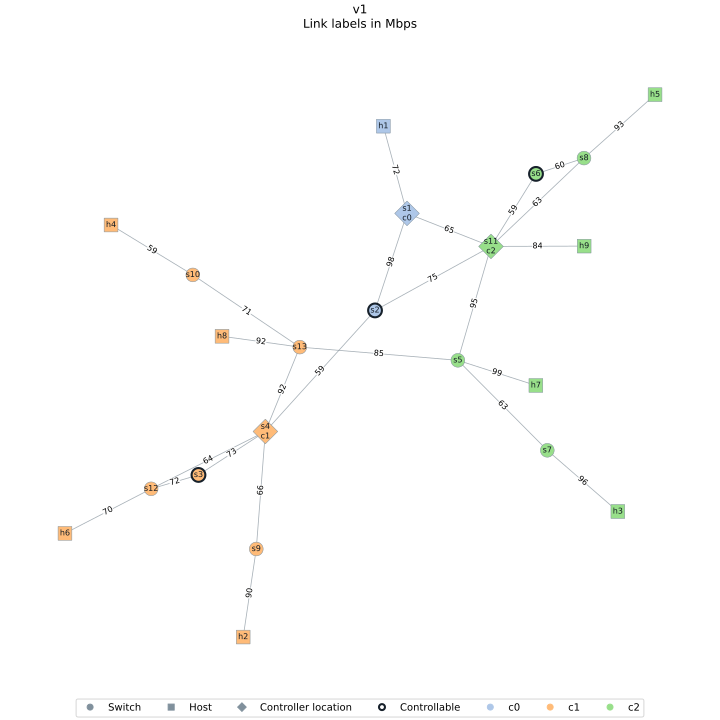

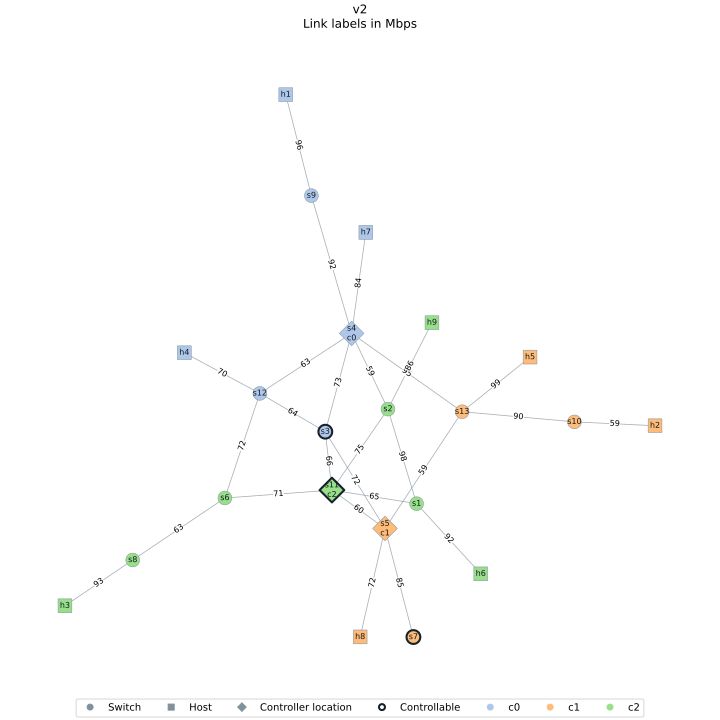

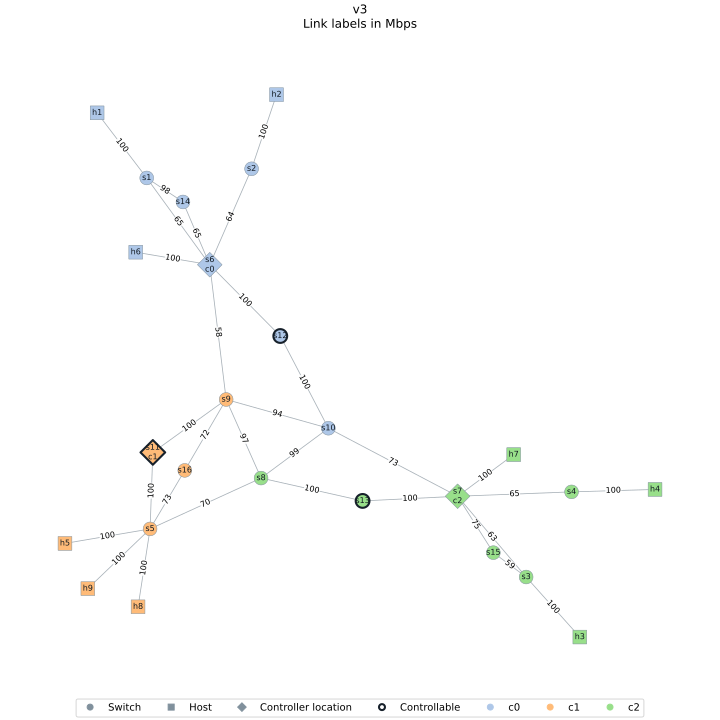

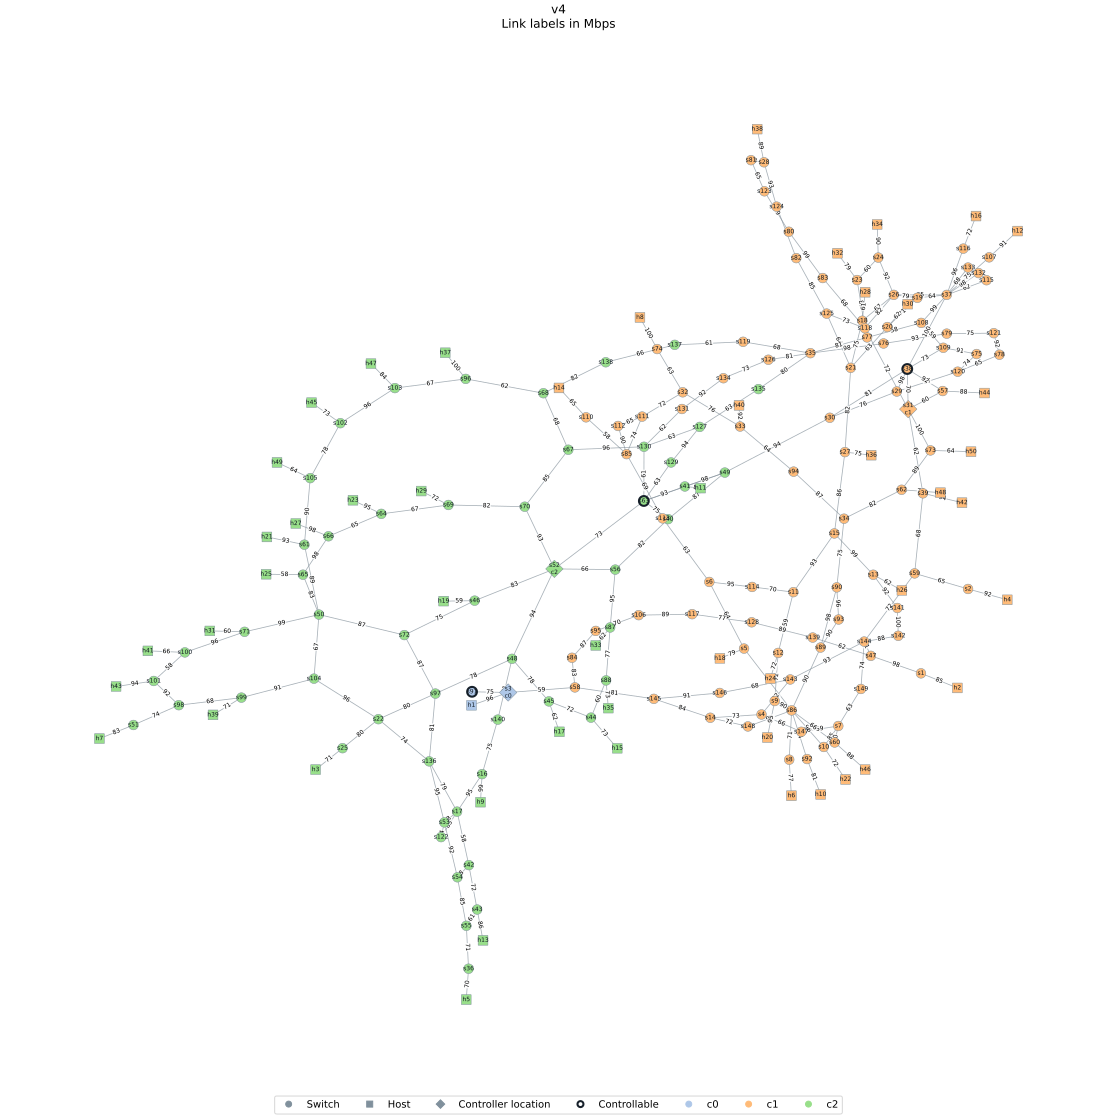

In [ ]:
show_network("v0")
show_network("v1")
show_network("v2")
show_network("v3")
show_network("v4")

## Prepare curriculum congestion environments

TrEnv 1 uses DC T0. TrEnvs 2 to 4 increase traffic from one controller domain, while TrEnv 5 increases traffic from all domains.


In [19]:
run(
    "data_preparation",
    "congestion",
    "--hosts",
    SOURCE_HOSTS,
    "--network",
    ROOT / "networks/v0.json",
)
# show_png(SOURCE_DATA / "train/dc_t0_trenv2.png")
# show_png(SOURCE_DATA / "train/dc_t0_trenv5.png")

/home/olzhas/sdn/EAGLE-replica/model/.venv/bin/python -m data_preparation congestion --hosts 9 --network /home/olzhas/sdn/EAGLE-replica/networks/v0.json
/home/olzhas/sdn/EAGLE-replica/datasets/9_hosts


## Start the V0 services externally

Run these commands in separate terminals, Ryu first.

```sh
ryu_controller/.venv/bin/python ryu_controller/launch_controllers.py --scenario networks/v0.json
sudo python3 mininet_nets/launch_topology.py --scenario networks/v0.json
```

The following cells discover their socket addresses. They assume both services use V0. Every model calibrates on its selected training conditions, pretrains its reward estimator, and freezes that estimator during actor–critic learning. The policy episode budget excludes calibration and pretraining.


/home/olzhas/sdn/EAGLE-replica/model/.venv/bin/python -m model.train --network v0.json --traffic synthetic --output dc_t0 --episodes 15 --pretrain-episodes 5 --seed 42
Training dc_t0 on cuda
Calibration dc_t0 | decision 1/36 | remaining 35 | mean reward -0.176806
Calibration dc_t0 | decision 2/36 | remaining 34 | mean reward 0.019538
Calibration dc_t0 | decision 3/36 | remaining 33 | mean reward -0.056111
Calibration dc_t0 | decision 4/36 | remaining 32 | mean reward 0.039510
Calibration dc_t0 | decision 5/36 | remaining 31 | mean reward 0.034923
Calibration dc_t0 | decision 6/36 | remaining 30 | mean reward 0.009801
Calibration dc_t0 | decision 7/36 | remaining 29 | mean reward -0.138210
Calibration dc_t0 | decision 8/36 | remaining 28 | mean reward 0.016842
Calibration dc_t0 | decision 9/36 | remaining 27 | mean reward -0.063686
Calibration dc_t0 | decision 10/36 | remaining 26 | mean reward -0.066532
Calibration dc_t0 | decision 11/36 | remaining 25 | mean reward -0.175703
Calibrati

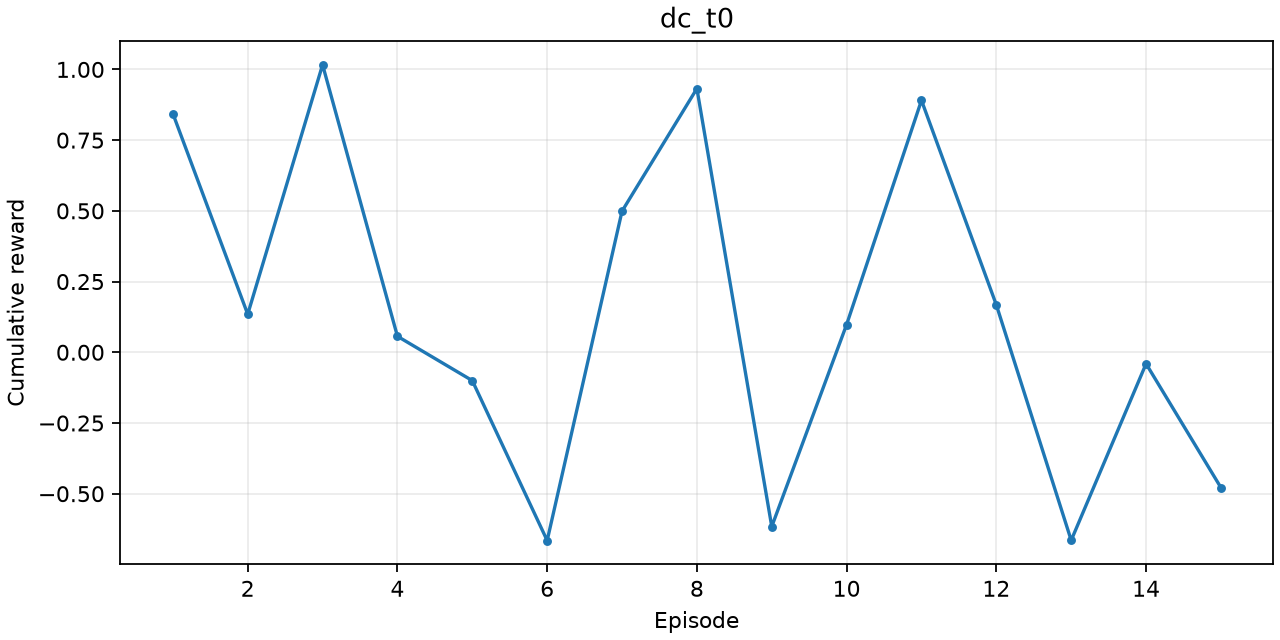

/home/olzhas/sdn/EAGLE-replica/model/.venv/bin/python -m model.train --network v0.json --traffic pcaps --output dc_pcaps --episodes 15 --pretrain-episodes 5 --seed 42
Training dc_pcaps on cuda
Calibration dc_pcap | decision 1/36 | remaining 35 | mean reward 0.086265
Calibration dc_pcap | decision 2/36 | remaining 34 | mean reward 0.042814
Calibration dc_pcap | decision 3/36 | remaining 33 | mean reward -0.121964
Calibration dc_pcap | decision 4/36 | remaining 32 | mean reward 0.031728
Calibration dc_pcap | decision 5/36 | remaining 31 | mean reward -0.048729
Calibration dc_pcap | decision 6/36 | remaining 30 | mean reward -0.059425
Calibration dc_pcap | decision 7/36 | remaining 29 | mean reward 0.010305
Calibration dc_pcap | decision 8/36 | remaining 28 | mean reward -0.083563
Calibration dc_pcap | decision 9/36 | remaining 27 | mean reward 0.001659
Calibration dc_pcap | decision 10/36 | remaining 26 | mean reward -0.133646
Calibration dc_pcap | decision 11/36 | remaining 25 | mean re

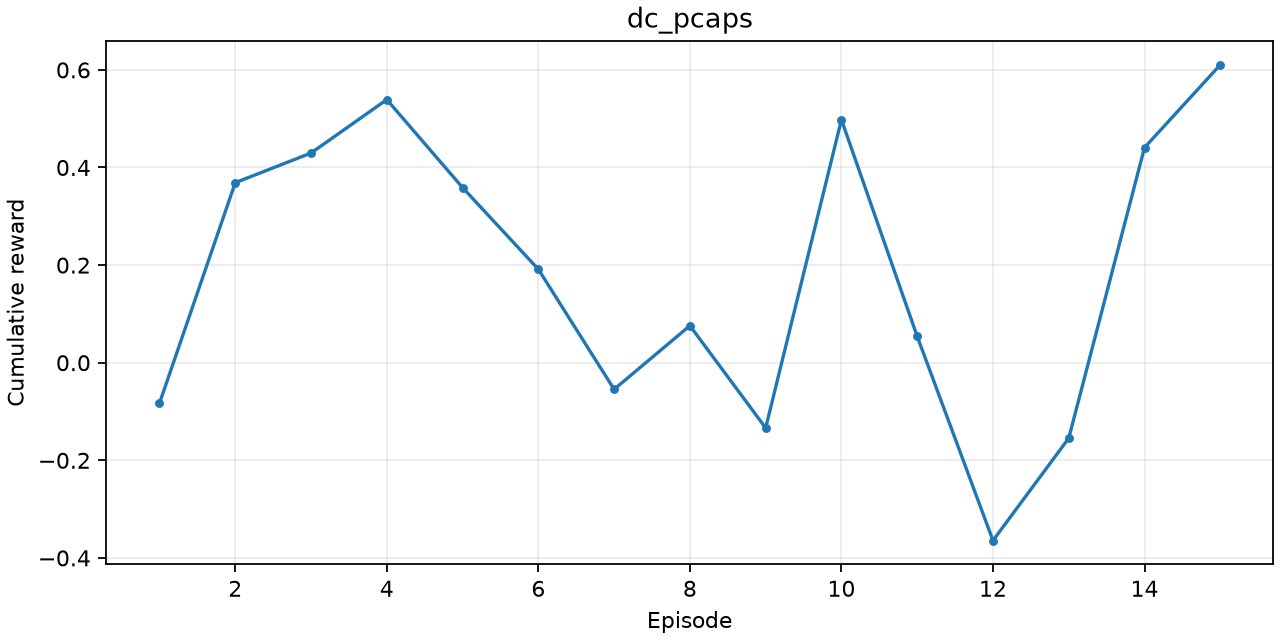

/home/olzhas/sdn/EAGLE-replica/model/.venv/bin/python -m model.train --network v0.json --traffic curriculum --output dc_full --episodes 15 --pretrain-episodes 5 --seed 42
Training dc_full on cuda
Calibration dc_t0 | decision 1/36 | remaining 35 | mean reward 0.000729
Calibration dc_t0 | decision 2/36 | remaining 34 | mean reward 0.012087
Calibration dc_t0 | decision 3/36 | remaining 33 | mean reward -0.125750
Calibration dc_t0 | decision 4/36 | remaining 32 | mean reward -0.012212
Calibration dc_t0 | decision 5/36 | remaining 31 | mean reward -0.046398
Calibration dc_t0 | decision 6/36 | remaining 30 | mean reward -0.040567
Calibration dc_t0 | decision 7/36 | remaining 29 | mean reward -0.043947
Calibration dc_t0 | decision 8/36 | remaining 28 | mean reward -0.150770
Calibration dc_t0 | decision 9/36 | remaining 27 | mean reward -0.111683
Calibration dc_t0 | decision 10/36 | remaining 26 | mean reward -0.088769
Calibration dc_t0 | decision 11/36 | remaining 25 | mean reward 0.078369
Ca

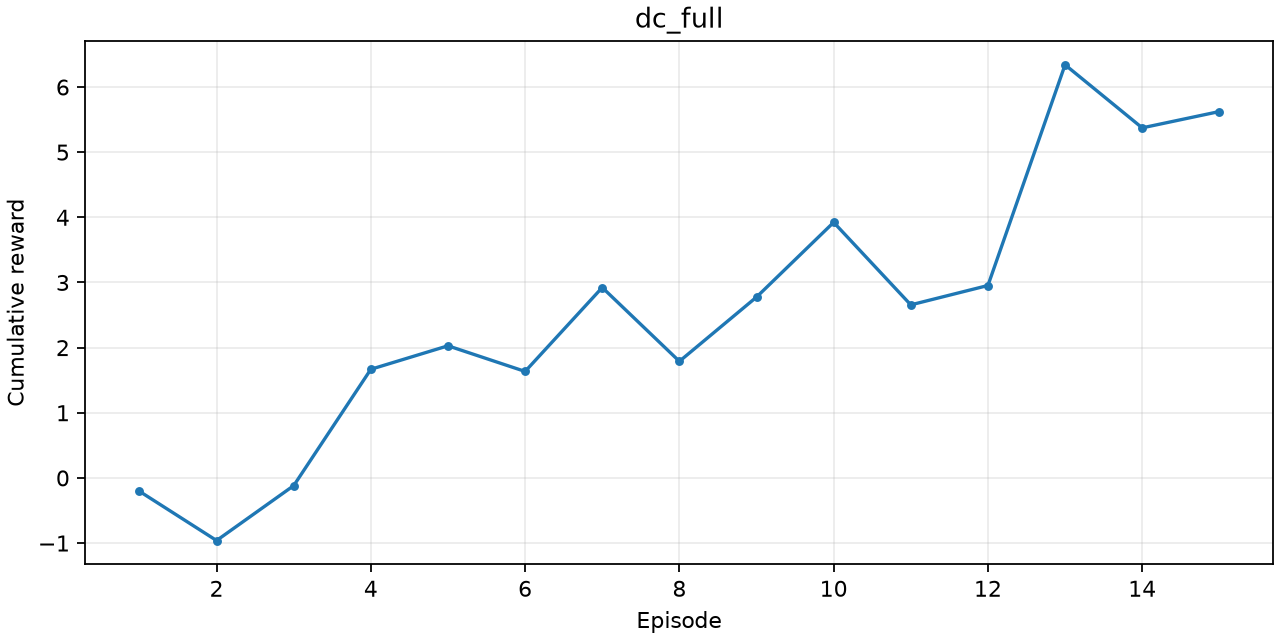

In [20]:
for traffic, name in zip(("synthetic", "pcaps", "curriculum"), SOURCE_MODELS):
    run(
        "model.train",
        "--network",
        "v0.json",
        "--traffic",
        traffic,
        "--output",
        name,
        "--episodes",
        EPISODES,
        "--pretrain-episodes",
        PRETRAIN_EPISODES,
        "--seed",
        SEED,
    )
    show_png(f"models/{name}.png")

To resume an interrupted run, repeat its original command with `--resume`. Each named inference file is accompanied by its CSV/PNG. The latest resumable state and event log are under `models/checkpoints/`.


## Post-train all three models on DC T5


/home/olzhas/sdn/EAGLE-replica/model/.venv/bin/python -m model.train --network v0.json --dataset dc_t5 --from-checkpoint dc_t0 --output dc_t0_t5 --episodes 5 --seed 42
Training dc_t0_t5 on cuda
dc_t5 episode 1/5 | decision 1/36 | remaining 35 | mean reward -0.261483
dc_t5 episode 1/5 | decision 2/36 | remaining 34 | mean reward -0.265434
dc_t5 episode 1/5 | decision 3/36 | remaining 33 | mean reward -0.210769
dc_t5 episode 1/5 | decision 4/36 | remaining 32 | mean reward -0.295921
dc_t5 episode 1/5 | decision 5/36 | remaining 31 | mean reward -0.244978
dc_t5 episode 1/5 | decision 6/36 | remaining 30 | mean reward -0.291373
dc_t5 episode 1/5 | decision 7/36 | remaining 29 | mean reward -0.259896
dc_t5 episode 1/5 | decision 8/36 | remaining 28 | mean reward -0.259174
dc_t5 episode 1/5 | decision 9/36 | remaining 27 | mean reward -0.260828
dc_t5 episode 1/5 | decision 10/36 | remaining 26 | mean reward -0.275277
dc_t5 episode 1/5 | decision 11/36 | remaining 25 | mean reward -0.244772
d

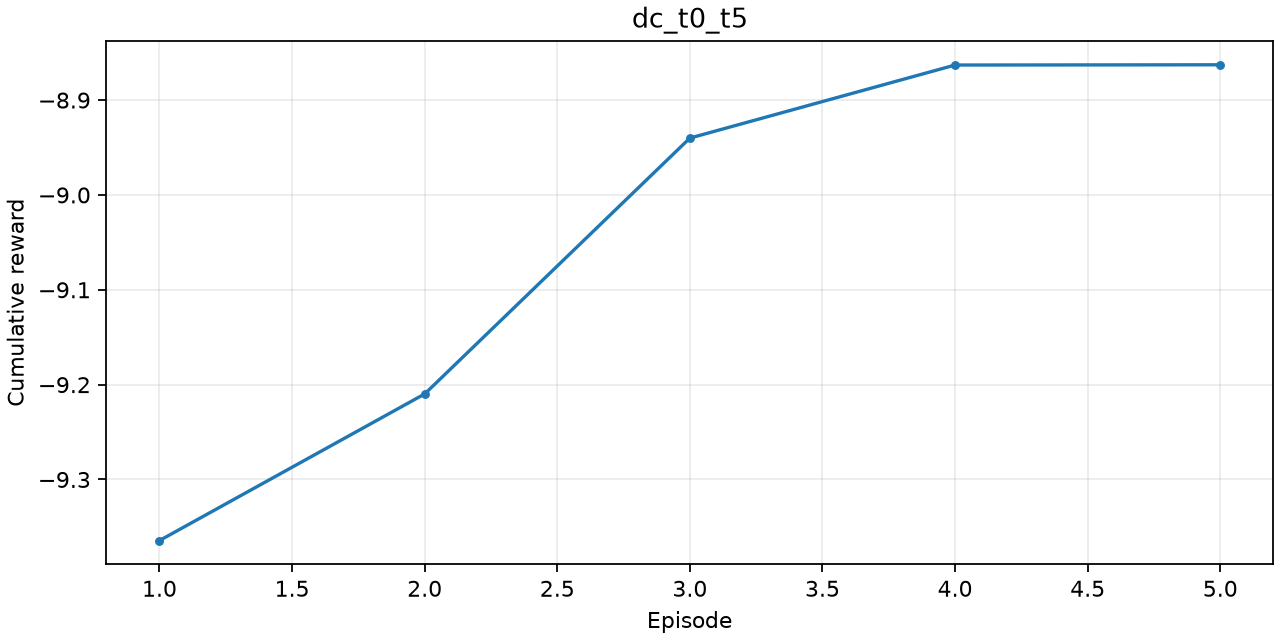

/home/olzhas/sdn/EAGLE-replica/model/.venv/bin/python -m model.train --network v0.json --dataset dc_t5 --from-checkpoint dc_pcaps --output dc_pcaps_t5 --episodes 5 --seed 42
Training dc_pcaps_t5 on cuda
dc_t5 episode 1/5 | decision 1/36 | remaining 35 | mean reward -0.258819
dc_t5 episode 1/5 | decision 2/36 | remaining 34 | mean reward -0.269301
dc_t5 episode 1/5 | decision 3/36 | remaining 33 | mean reward -0.195833
dc_t5 episode 1/5 | decision 4/36 | remaining 32 | mean reward -0.287326
dc_t5 episode 1/5 | decision 5/36 | remaining 31 | mean reward -0.245010
dc_t5 episode 1/5 | decision 6/36 | remaining 30 | mean reward -0.291614
dc_t5 episode 1/5 | decision 7/36 | remaining 29 | mean reward -0.257731
dc_t5 episode 1/5 | decision 8/36 | remaining 28 | mean reward -0.257413
dc_t5 episode 1/5 | decision 9/36 | remaining 27 | mean reward -0.248702
dc_t5 episode 1/5 | decision 10/36 | remaining 26 | mean reward -0.271632
dc_t5 episode 1/5 | decision 11/36 | remaining 25 | mean reward -0

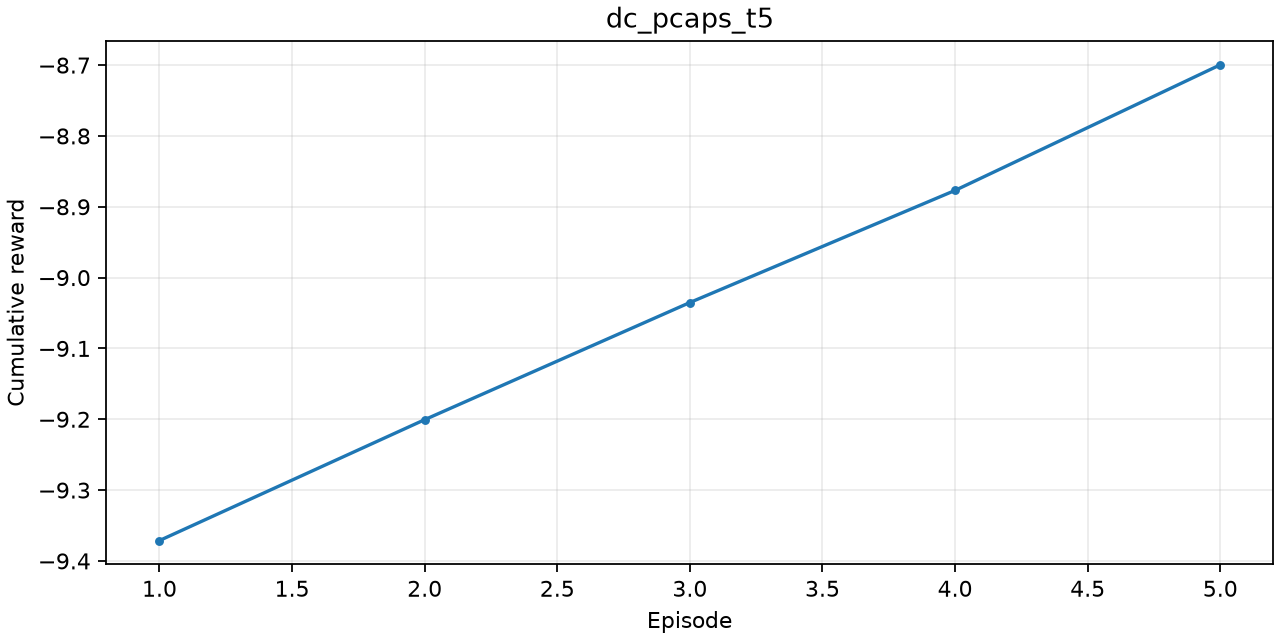

/home/olzhas/sdn/EAGLE-replica/model/.venv/bin/python -m model.train --network v0.json --dataset dc_t5 --from-checkpoint dc_full --output dc_full_t5 --episodes 5 --seed 42
Training dc_full_t5 on cuda
dc_t5 episode 1/5 | decision 1/36 | remaining 35 | mean reward -0.261796
dc_t5 episode 1/5 | decision 2/36 | remaining 34 | mean reward -0.264717
dc_t5 episode 1/5 | decision 3/36 | remaining 33 | mean reward -0.194418
dc_t5 episode 1/5 | decision 4/36 | remaining 32 | mean reward -0.310354
dc_t5 episode 1/5 | decision 5/36 | remaining 31 | mean reward -0.267151
dc_t5 episode 1/5 | decision 6/36 | remaining 30 | mean reward -0.288459
dc_t5 episode 1/5 | decision 7/36 | remaining 29 | mean reward -0.288277
dc_t5 episode 1/5 | decision 8/36 | remaining 28 | mean reward -0.252708
dc_t5 episode 1/5 | decision 9/36 | remaining 27 | mean reward -0.221998
dc_t5 episode 1/5 | decision 10/36 | remaining 26 | mean reward -0.272320
dc_t5 episode 1/5 | decision 11/36 | remaining 25 | mean reward -0.25

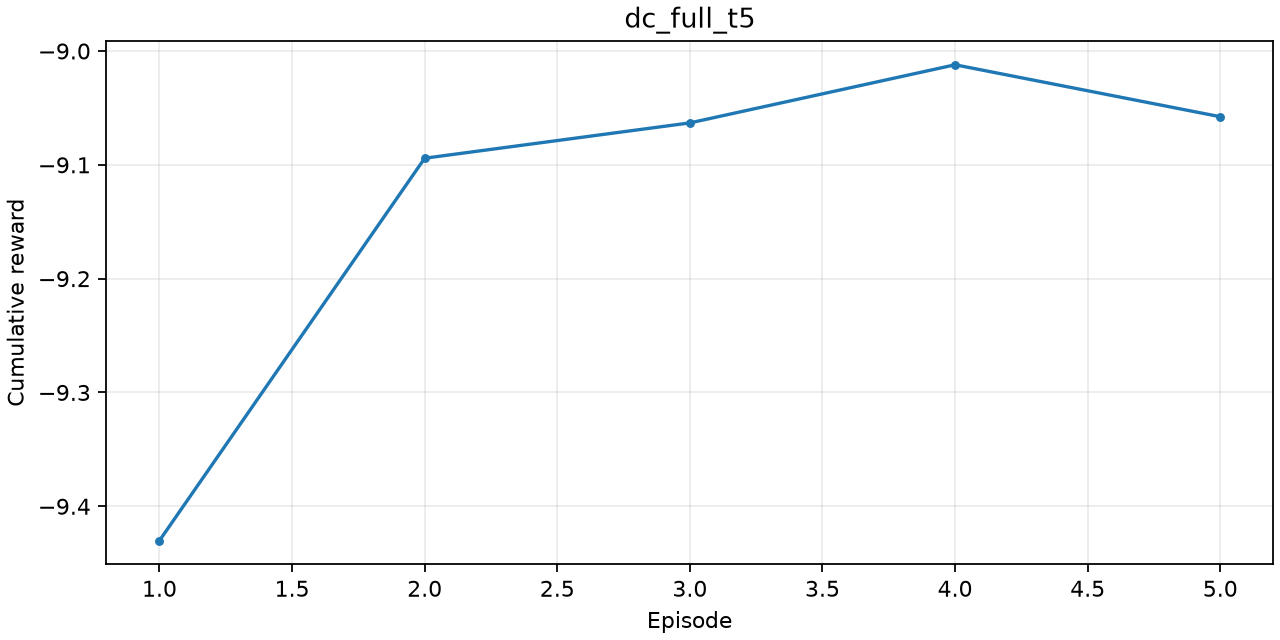

In [30]:
assert (SOURCE_DATA / "train/dc_t5.json").is_file(), (
    "Create dc_t5.json with data_preparation/tmp_convert.py first"
)
POSTTRAIN_MODELS = [f"{name}_t5" for name in SOURCE_MODELS]
for source, name in zip(SOURCE_MODELS, POSTTRAIN_MODELS):
    options = ["--resume"] if (ROOT / f"models/checkpoints/{name}.pth").exists() else []
    run(
        "model.train",
        "--network",
        "v0.json",
        "--dataset",
        "dc_t5",
        "--from-checkpoint",
        source,
        "--output",
        name,
        "--episodes",
        POSTTRAIN_EPISODES,
        "--seed",
        SEED,
        *options,
    )
    show_png(f"models/{name}.png")
MODELS = POSTTRAIN_MODELS.copy()


## Train pruning variants

Use the same synthetic source and episode budget. The default `dc_t0` model provides dynamic pruning. These two additional models provide the dense and static-pruning reward curves.


/home/olzhas/sdn/EAGLE-replica/model/.venv/bin/python -m model.train --network v0.json --traffic synthetic --output dc_t0_no_pruning --settings settings/no_pruning.json --episodes 15 --pretrain-episodes 5 --seed 42
Training dc_t0_no_pruning on cuda
Calibration dc_t0 | decision 1/36 | remaining 35 | mean reward -0.133023
Calibration dc_t0 | decision 2/36 | remaining 34 | mean reward 0.012880
Calibration dc_t0 | decision 3/36 | remaining 33 | mean reward -0.004059
Calibration dc_t0 | decision 4/36 | remaining 32 | mean reward 0.026136
Calibration dc_t0 | decision 5/36 | remaining 31 | mean reward -0.088951
Calibration dc_t0 | decision 6/36 | remaining 30 | mean reward -0.004608
Calibration dc_t0 | decision 7/36 | remaining 29 | mean reward -0.017788
Calibration dc_t0 | decision 8/36 | remaining 28 | mean reward 0.024798
Calibration dc_t0 | decision 9/36 | remaining 27 | mean reward -0.111505
Calibration dc_t0 | decision 10/36 | remaining 26 | mean reward -0.142460
Calibration dc_t0 | dec

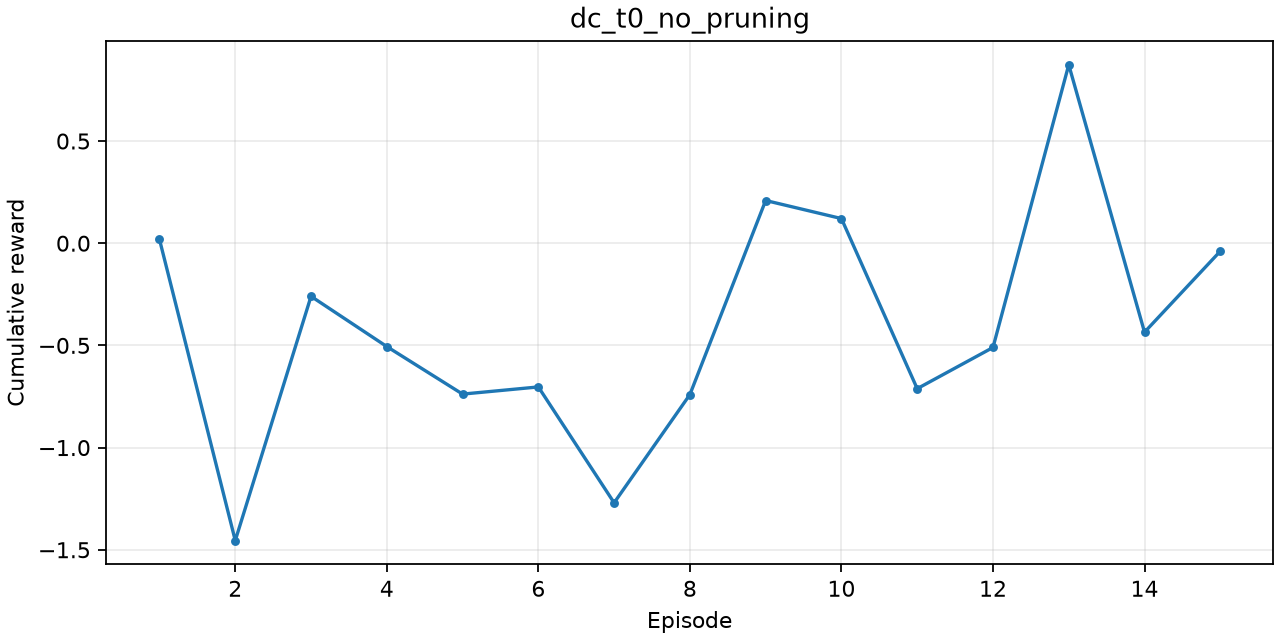

/home/olzhas/sdn/EAGLE-replica/model/.venv/bin/python -m model.train --network v0.json --traffic synthetic --output dc_t0_static_pruning --settings settings/static_pruning.json --episodes 15 --pretrain-episodes 5 --seed 42
Training dc_t0_static_pruning on cuda
Calibration dc_t0 | decision 1/36 | remaining 35 | mean reward -0.092821
Calibration dc_t0 | decision 2/36 | remaining 34 | mean reward 0.045545
Calibration dc_t0 | decision 3/36 | remaining 33 | mean reward 0.006725
Calibration dc_t0 | decision 4/36 | remaining 32 | mean reward 0.001244
Calibration dc_t0 | decision 5/36 | remaining 31 | mean reward 0.002694
Calibration dc_t0 | decision 6/36 | remaining 30 | mean reward -0.020708
Calibration dc_t0 | decision 7/36 | remaining 29 | mean reward -0.005913
Calibration dc_t0 | decision 8/36 | remaining 28 | mean reward -0.000868
Calibration dc_t0 | decision 9/36 | remaining 27 | mean reward -0.093541
Calibration dc_t0 | decision 10/36 | remaining 26 | mean reward -0.139380
Calibration 

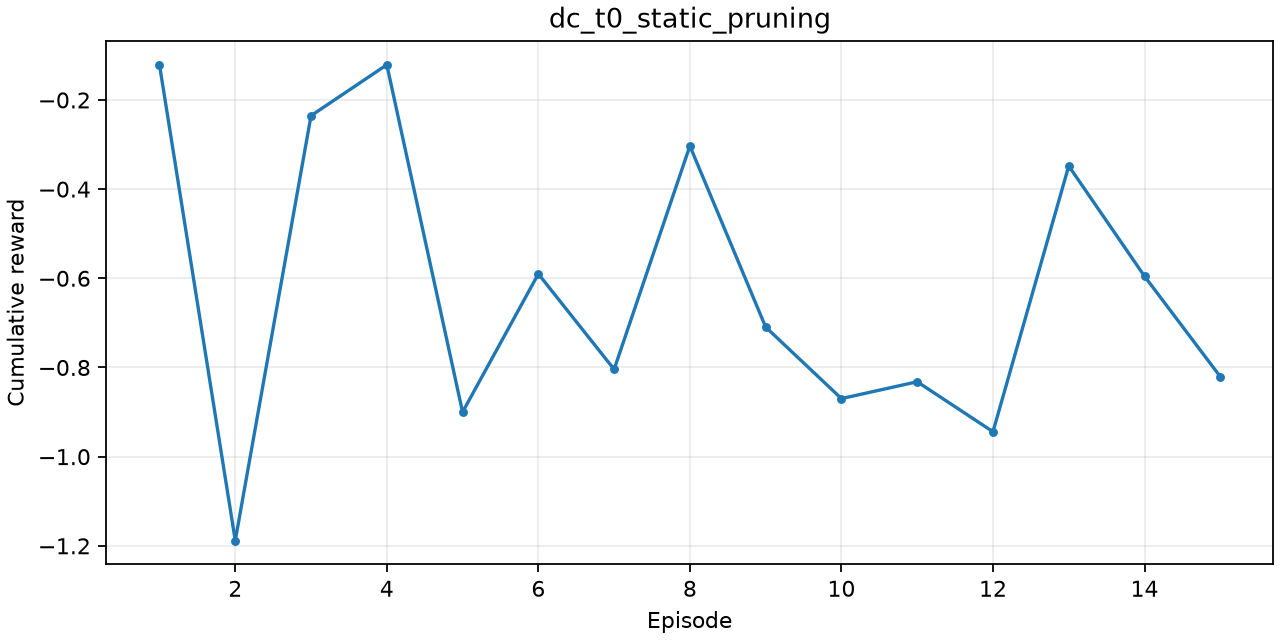

In [4]:
for name, settings in (
    ("dc_t0_no_pruning", "settings/no_pruning.json"),
    ("dc_t0_static_pruning", "settings/static_pruning.json"),
):
    run(
        "model.train",
        "--network",
        "v0.json",
        "--traffic",
        "synthetic",
        "--output",
        name,
        "--settings",
        settings,
        "--episodes",
        EPISODES,
        "--pretrain-episodes",
        PRETRAIN_EPISODES,
        "--seed",
        SEED,
    )
    show_png(f"models/{name}.png")

## Evaluation 2 — traffic embeddings on V0

Keep V0 running. Collect one embedding at the first post-reset observation with delivered traffic from T0, T1, Megalodon T2, T3, T4, and TrEnvs 2 to 5. All switches stay on during collection. All nine vectors are projected together.


/home/olzhas/sdn/EAGLE-replica/model/.venv/bin/python -m model.eval_traffic_embeddings --model dc_t0_t5 --seed 42


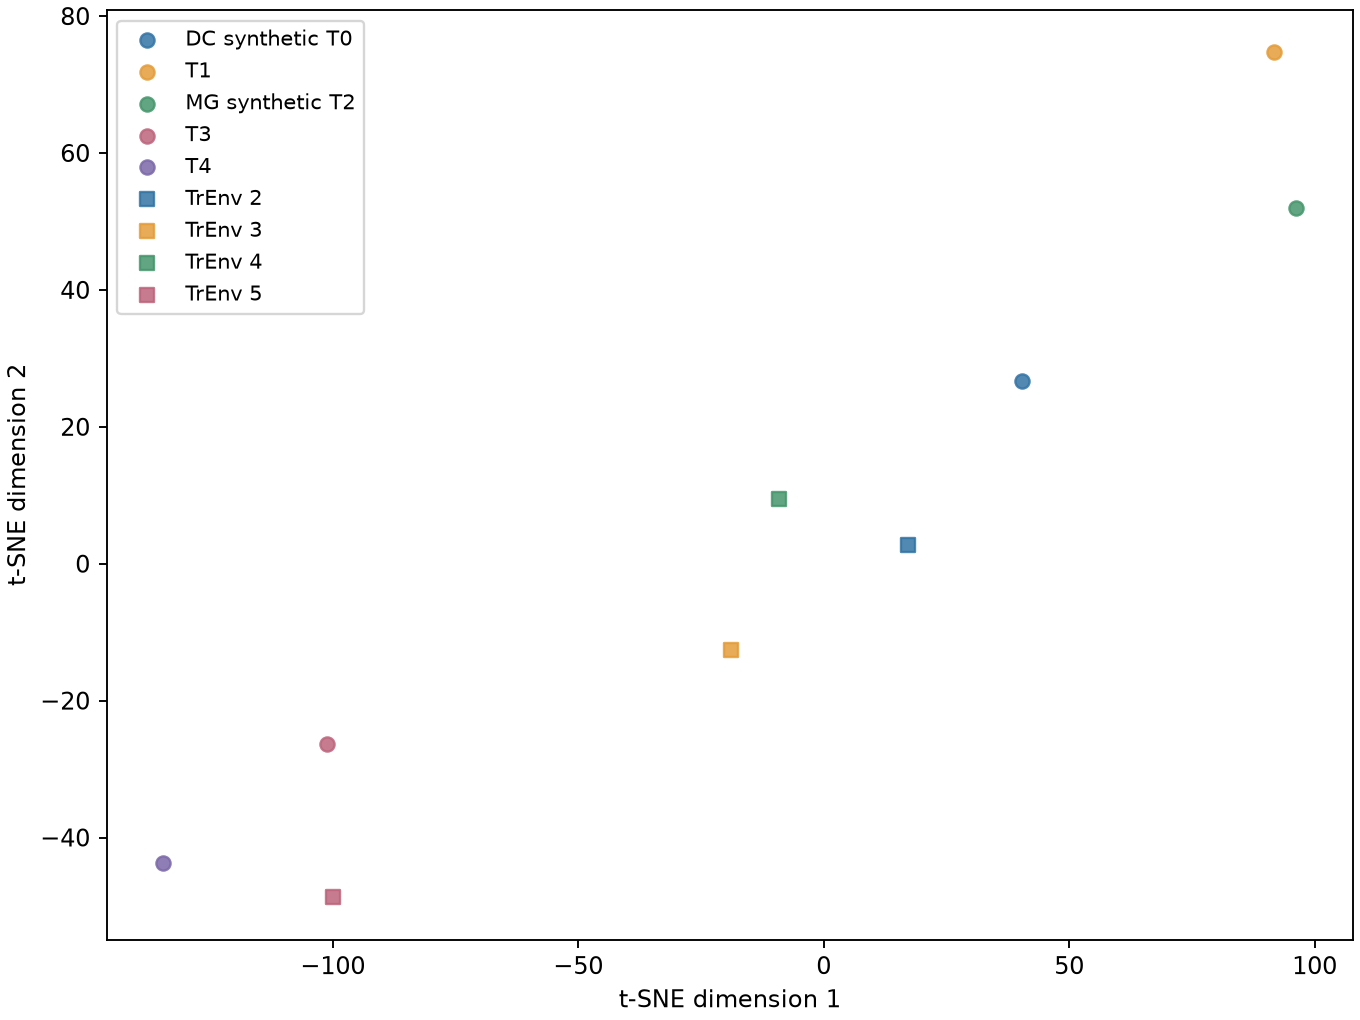

In [37]:
run("model.eval_traffic_embeddings", "--model", MODELS[0], "--seed", SEED)
show_png("eval/traffic_embeddings.png")

## Evaluation 3 — model comparison across datasets

Keep V0 running. Each repetition uses `SEED + i` for all three models and the matched all-on baseline. The source dataset group has four entries. The load group contains T1, T3, and T4, with Megalodon T2 already included among the source datasets. The congestion group contains TrEnvs 2 to 5.


/home/olzhas/sdn/EAGLE-replica/model/.venv/bin/python -m model.eval_datasets --models dc_t0_t5 dc_pcaps_t5 dc_full_t5 --episodes 5 --repetitions 1 --seed 42
v0 | dc_t0 | baseline | repetition 1/1 | episode 1/5
v0 | dc_t0 | baseline | repetition 1/1 | episode 2/5
v0 | dc_t0 | baseline | repetition 1/1 | episode 3/5
v0 | dc_t0 | baseline | repetition 1/1 | episode 4/5
v0 | dc_t0 | baseline | repetition 1/1 | episode 5/5
v0 | dc_t0 | dc_t0_t5 | repetition 1/1 | episode 1/5
v0 | dc_t0 | dc_t0_t5 | repetition 1/1 | episode 2/5
v0 | dc_t0 | dc_t0_t5 | repetition 1/1 | episode 3/5
v0 | dc_t0 | dc_t0_t5 | repetition 1/1 | episode 4/5
v0 | dc_t0 | dc_t0_t5 | repetition 1/1 | episode 5/5
v0 | dc_t0 | dc_pcaps_t5 | repetition 1/1 | episode 1/5
v0 | dc_t0 | dc_pcaps_t5 | repetition 1/1 | episode 2/5
v0 | dc_t0 | dc_pcaps_t5 | repetition 1/1 | episode 3/5
v0 | dc_t0 | dc_pcaps_t5 | repetition 1/1 | episode 4/5
v0 | dc_t0 | dc_pcaps_t5 | repetition 1/1 | episode 5/5
v0 | dc_t0 | dc_full_t5 | repetit

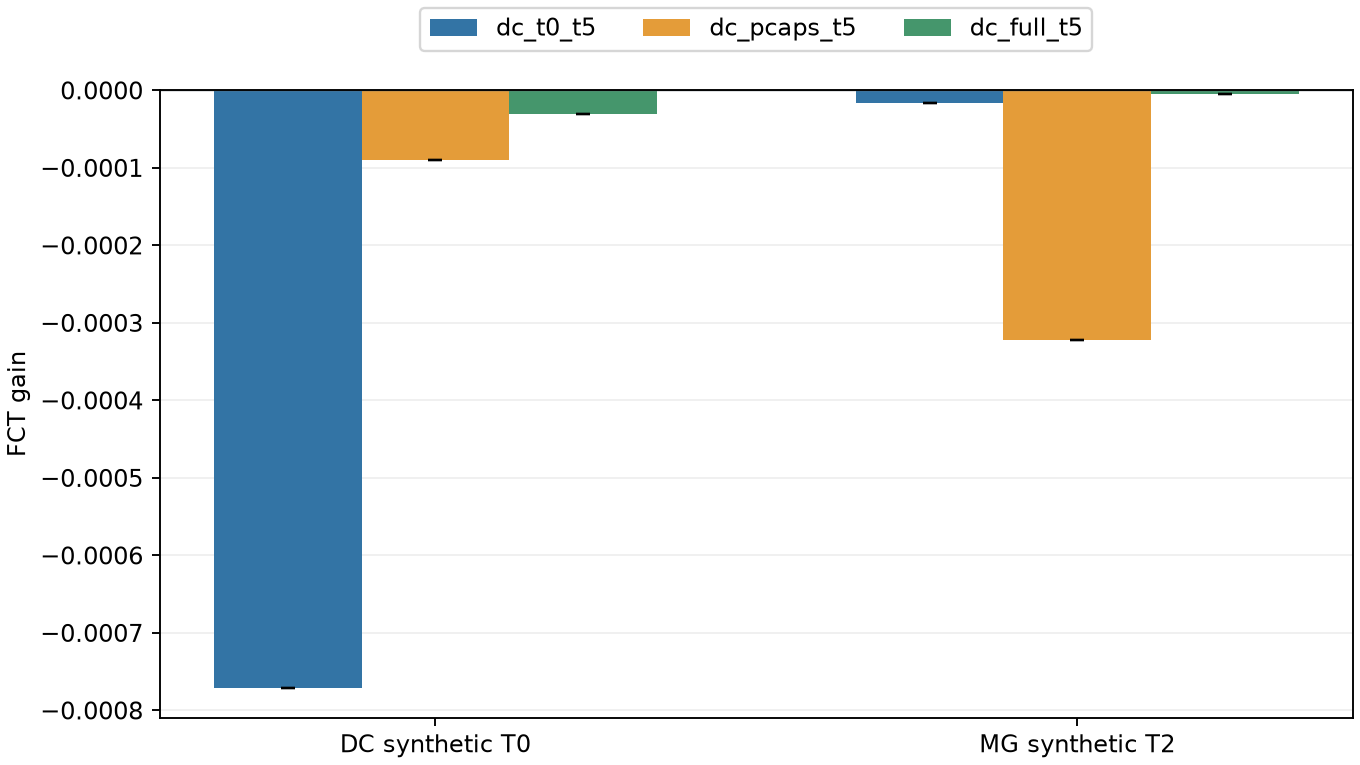

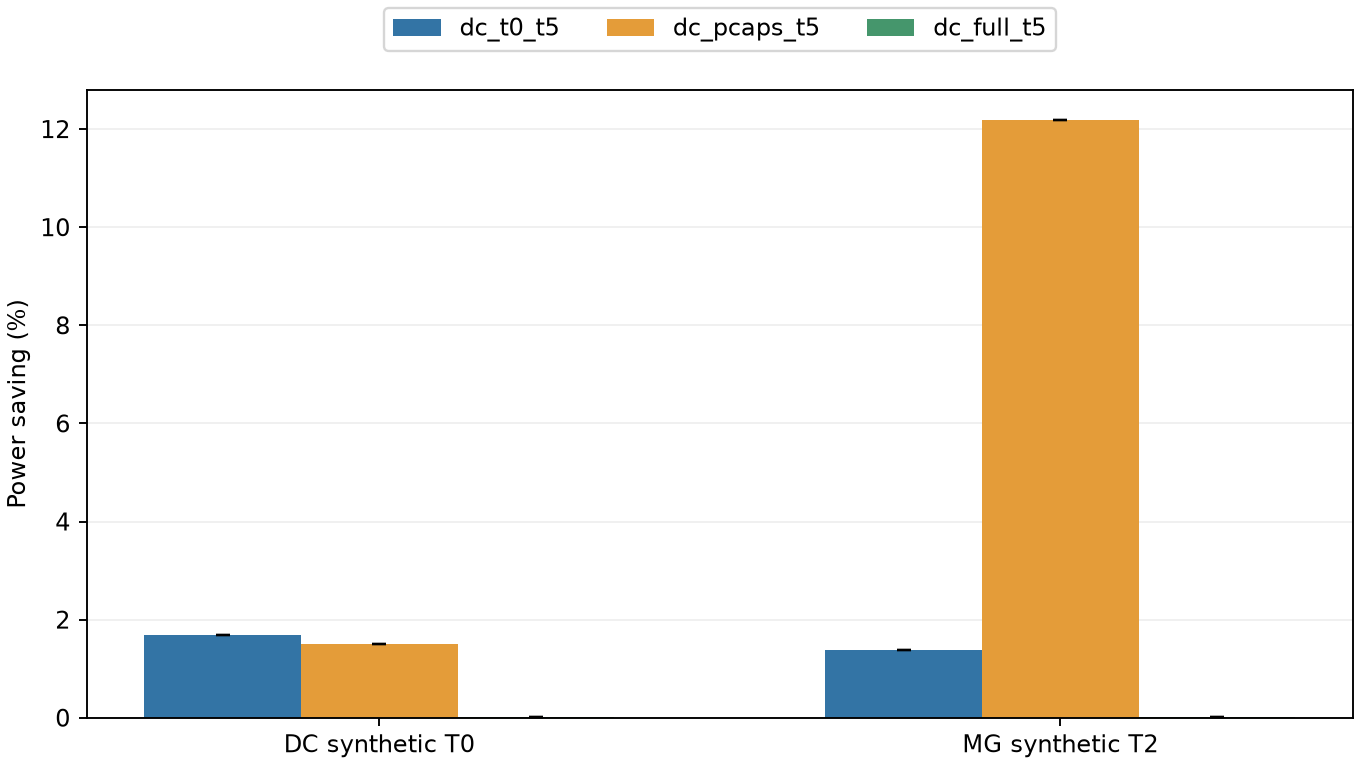

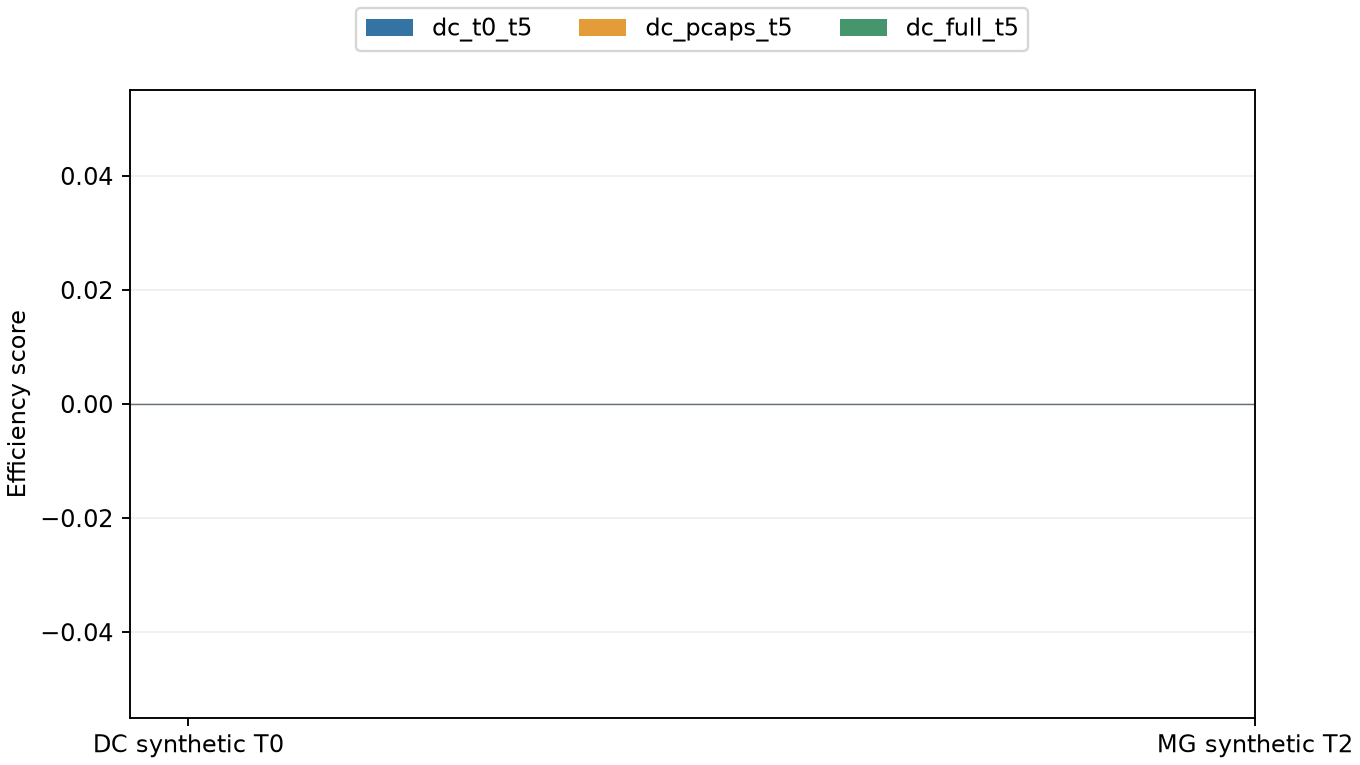

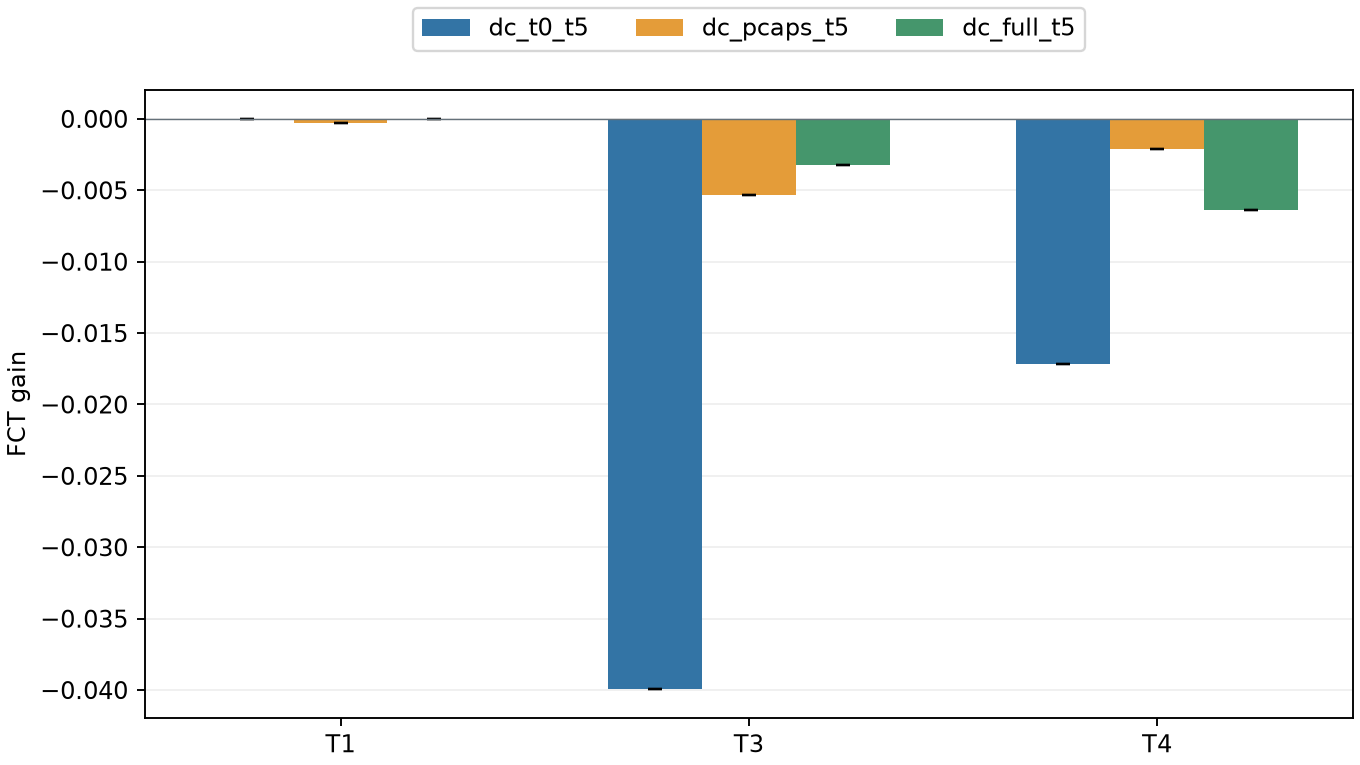

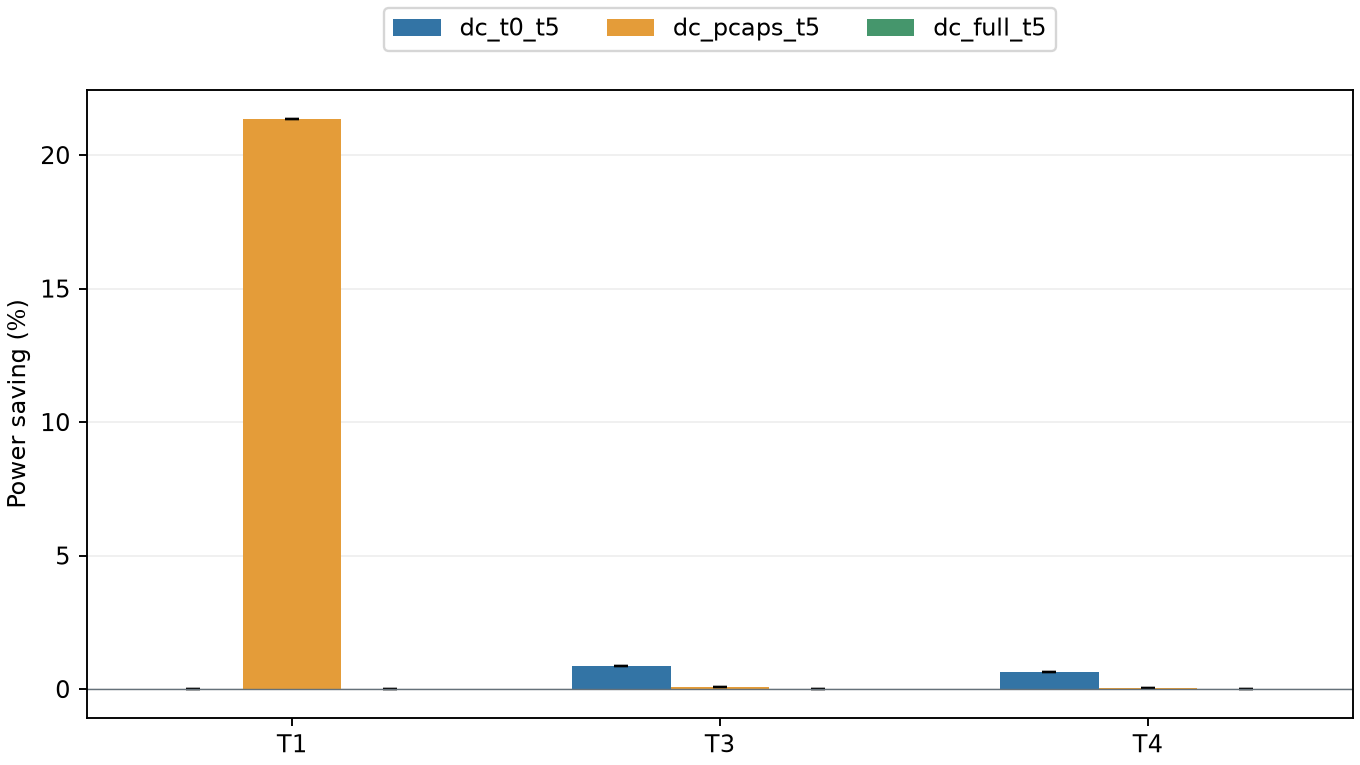

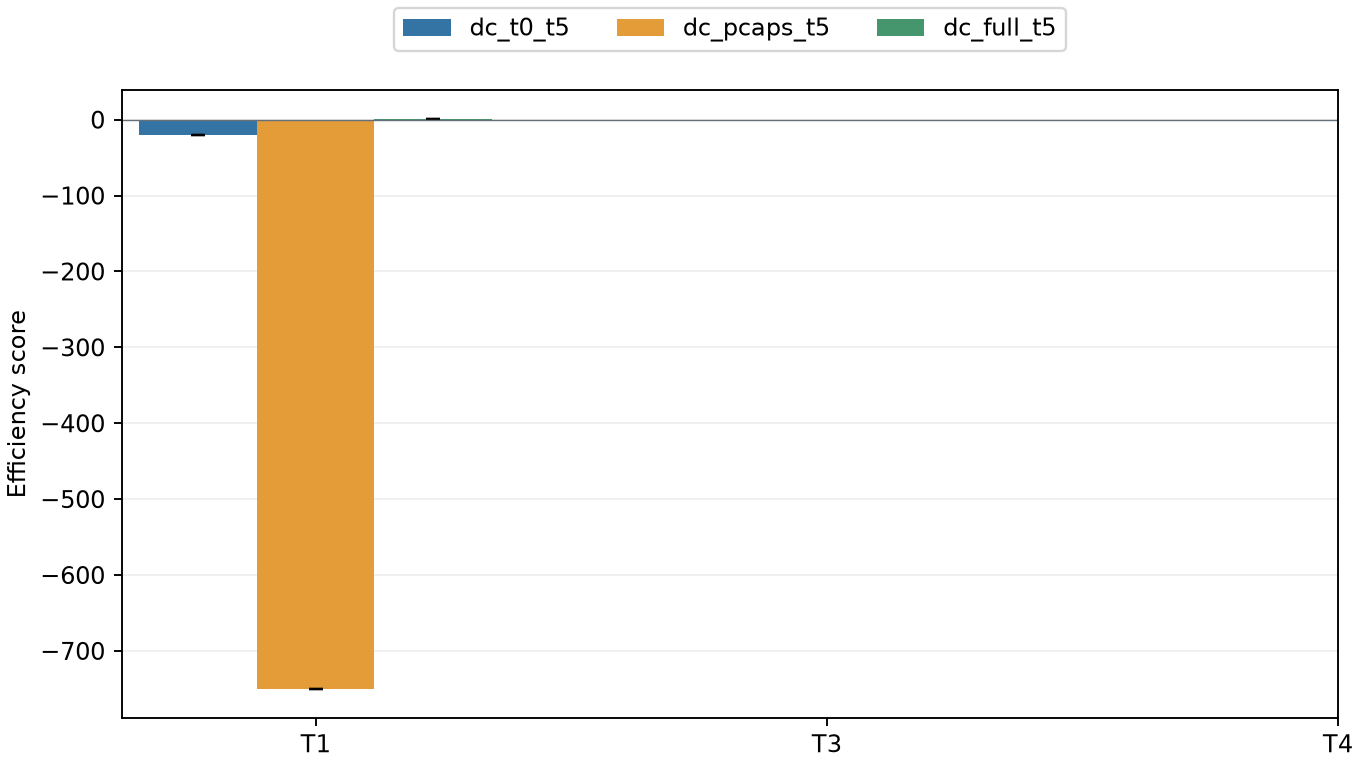

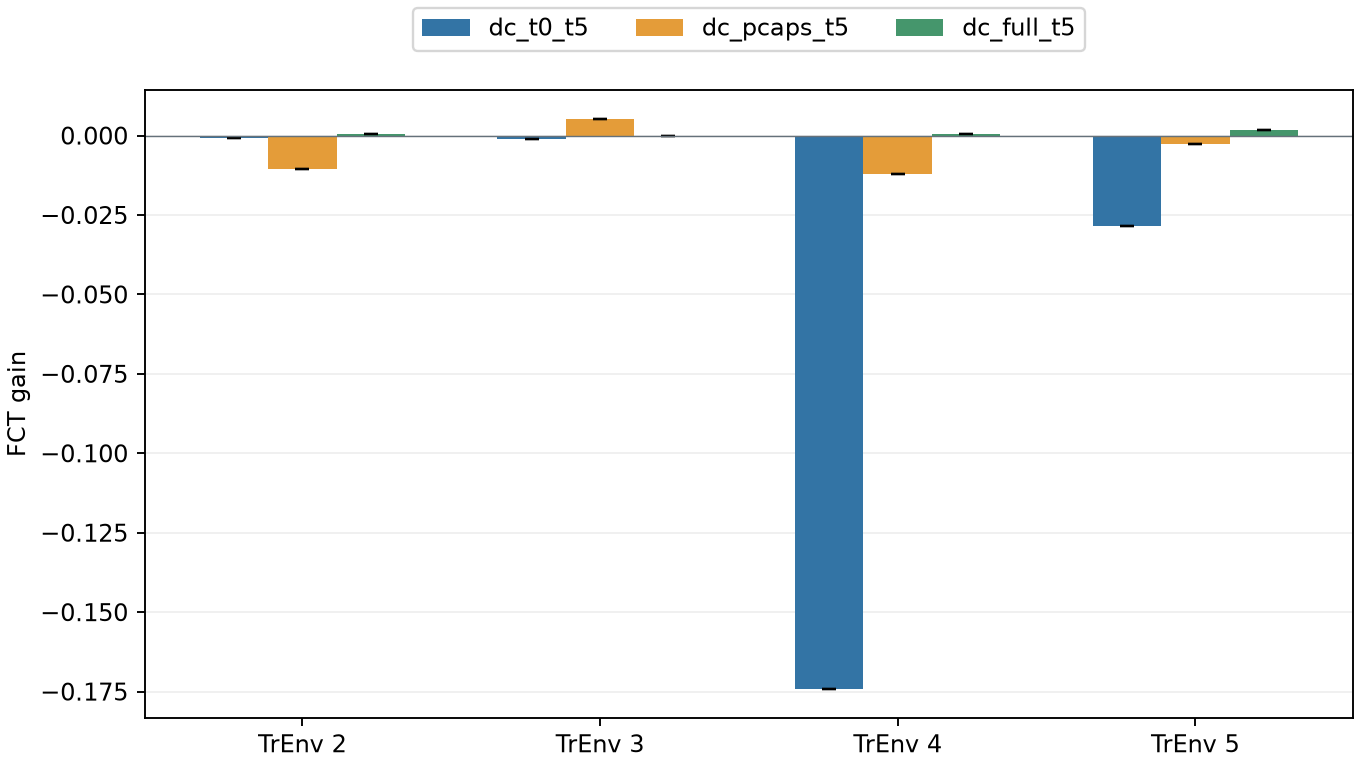

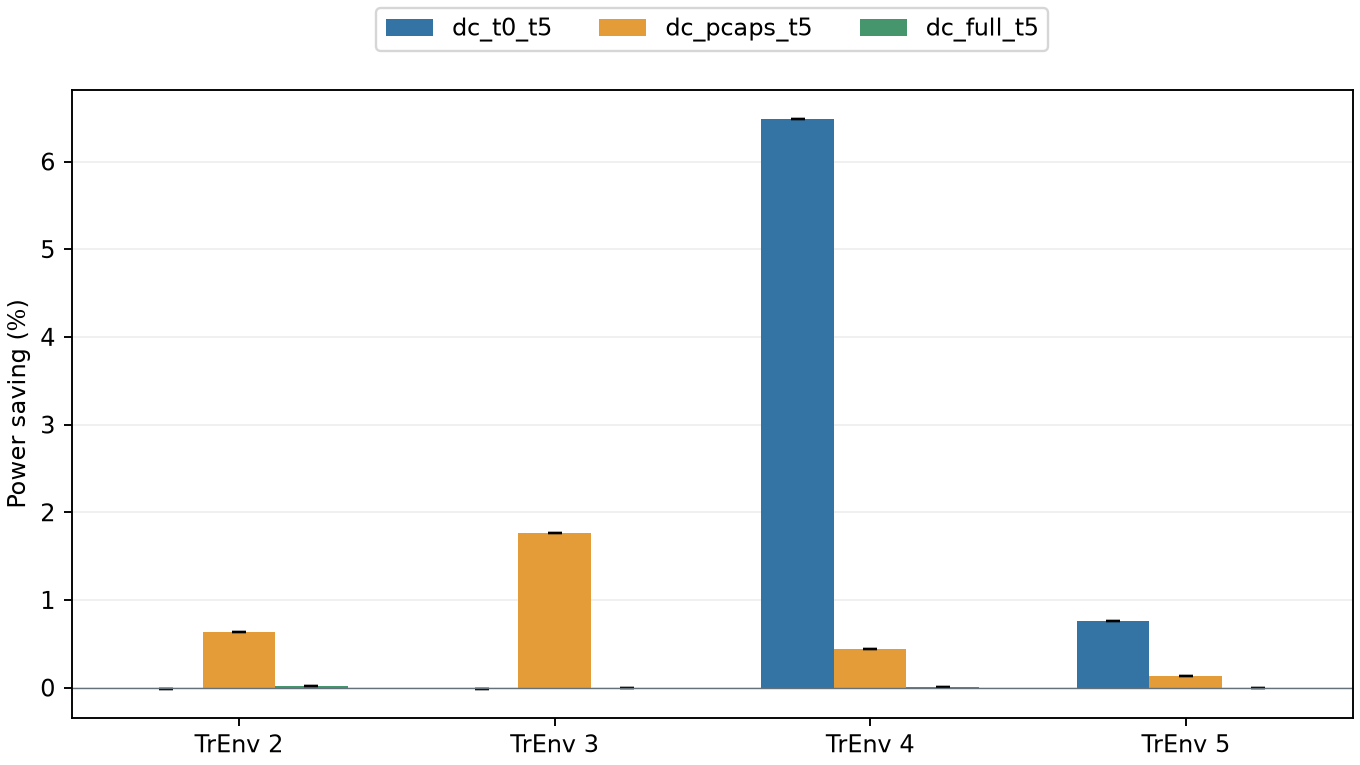

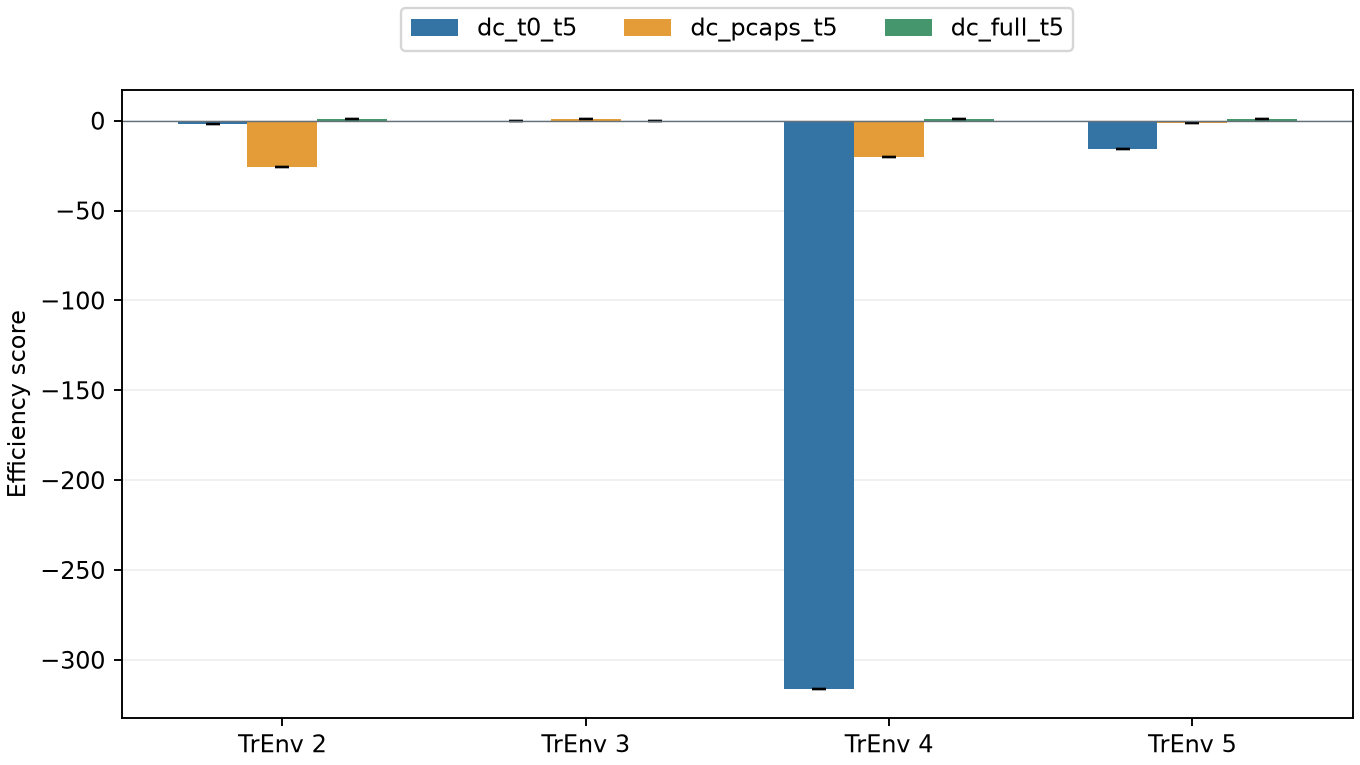

In [39]:
run(
    "model.eval_datasets",
    "--models",
    *MODELS,
    "--episodes",
    EVAL_EPISODES,
    "--repetitions",
    REPETITIONS,
    "--seed",
    SEED,
)
for group in ("sources", "loads", "congestions"):
    for metric in ("fct_gain", "power_saving", "efficiency"):
        show_png(f"eval/datasets_{group}_{metric}.png")

## Evaluation 6 — enabled controllable switches

Keep V0 running. Each model and the all-on baseline run a single episode with the same seed. The plot shows the sum of their binary actions after every joint decision, and the legend includes the final switch count. `--dataset` can select another prepared test dataset. Runs extending beyond the dataset include idle time after its traffic ends.


/home/olzhas/sdn/EAGLE-replica/model/.venv/bin/python -m model.eval_switches --network v0.json --steps 5 --models dc_t0 dc_pcaps dc_full --seed 42 --dataset dc_t1
baseline | decision 1/5 | remaining 4 | mean reward -0.170645
baseline | decision 2/5 | remaining 3 | mean reward -0.141815
baseline | decision 3/5 | remaining 2 | mean reward -0.162747
baseline | decision 4/5 | remaining 1 | mean reward -0.168898
baseline | decision 5/5 | remaining 0 | mean reward -0.207127
dc_t0 | decision 1/5 | remaining 4 | mean reward -0.190542
dc_t0 | decision 2/5 | remaining 3 | mean reward -0.136460
dc_t0 | decision 3/5 | remaining 2 | mean reward -0.182506
dc_t0 | decision 4/5 | remaining 1 | mean reward -0.130545
dc_t0 | decision 5/5 | remaining 0 | mean reward -0.188767
dc_pcaps | decision 1/5 | remaining 4 | mean reward -0.201878
dc_pcaps | decision 2/5 | remaining 3 | mean reward -0.199553
dc_pcaps | decision 3/5 | remaining 2 | mean reward -0.151106
dc_pcaps | decision 4/5 | remaining 1 | mean r

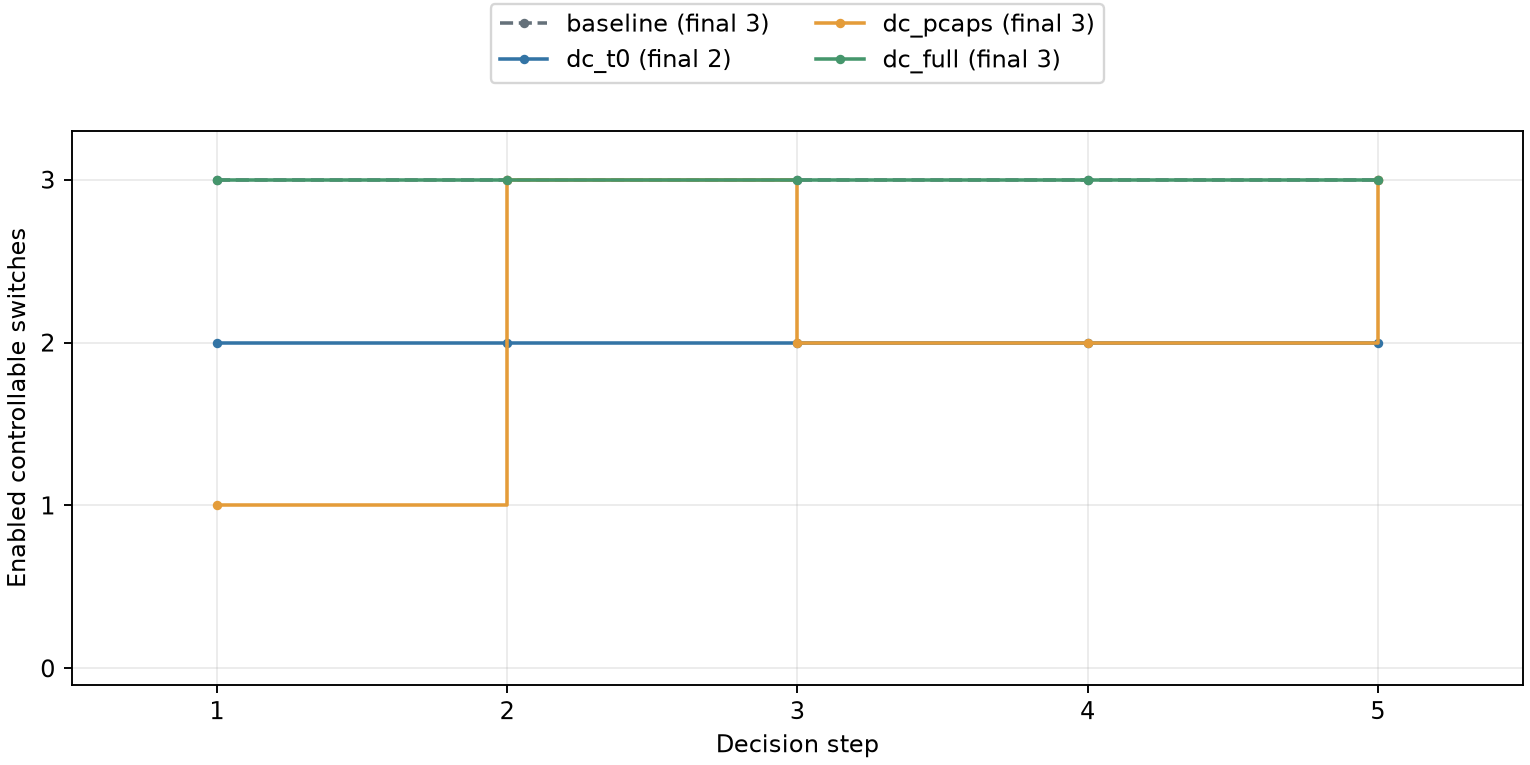

In [41]:
SWITCH_STEPS = MIN_DECISIONS
run(
    "model.eval_switches",
    "--network",
    "v0.json",
    "--steps",
    5,
    "--models",
    *["dc_t0", "dc_pcaps", "dc_full"],
    "--seed",
    SEED,
    "--dataset",
    "dc_t1",
)
show_png("eval/switches_v0.png")

## Evaluations 1 and 4 — collect one topology at a time

Set `CURRENT_TOPOLOGY` to the topology running outside the notebook, then execute the collection cell. Repeat this section for V0 through V4, restarting both external services between topologies. V4 automatically uses its larger-host test datasets.

Evaluation 1 collects 16 all-on DC T0 embeddings per topology. Evaluation 4 evaluates the three frozen models and their all-on baseline on DC PCAPs. Its reward CSVs average raw episode returns across repetitions.


In [26]:
CURRENT_TOPOLOGY = "v0"  # Change to v1, v2, v3, and v4 after external restarts.
assert CURRENT_TOPOLOGY in {f"v{i}" for i in range(5)}
print("Expected running network", ROOT / f"networks/{CURRENT_TOPOLOGY}.json")

Expected running network /home/olzhas/sdn/EAGLE-replica/networks/v0.json


/home/olzhas/sdn/EAGLE-replica/model/.venv/bin/python -m model.eval_topology_embeddings --network v0.json --model dc_t0 --seed 42
/home/olzhas/sdn/EAGLE-replica/model/.venv/bin/python -m model.eval_topologies --network v0.json --models dc_t0 dc_pcaps dc_full --episodes 5 --repetitions 1 --seed 42
v0 | dc_t0 | baseline | repetition 1/1 | episode 1/5
v0 | dc_t0 | baseline | repetition 1/1 | episode 2/5
v0 | dc_t0 | baseline | repetition 1/1 | episode 3/5
v0 | dc_t0 | baseline | repetition 1/1 | episode 4/5
v0 | dc_t0 | baseline | repetition 1/1 | episode 5/5
v0 | dc_t0 | dc_t0 | repetition 1/1 | episode 1/5
v0 | dc_t0 | dc_t0 | repetition 1/1 | episode 2/5
v0 | dc_t0 | dc_t0 | repetition 1/1 | episode 3/5
v0 | dc_t0 | dc_t0 | repetition 1/1 | episode 4/5
v0 | dc_t0 | dc_t0 | repetition 1/1 | episode 5/5
v0 | dc_t0 | dc_pcaps | repetition 1/1 | episode 1/5
v0 | dc_t0 | dc_pcaps | repetition 1/1 | episode 2/5
v0 | dc_t0 | dc_pcaps | repetition 1/1 | episode 3/5
v0 | dc_t0 | dc_pcaps | repe

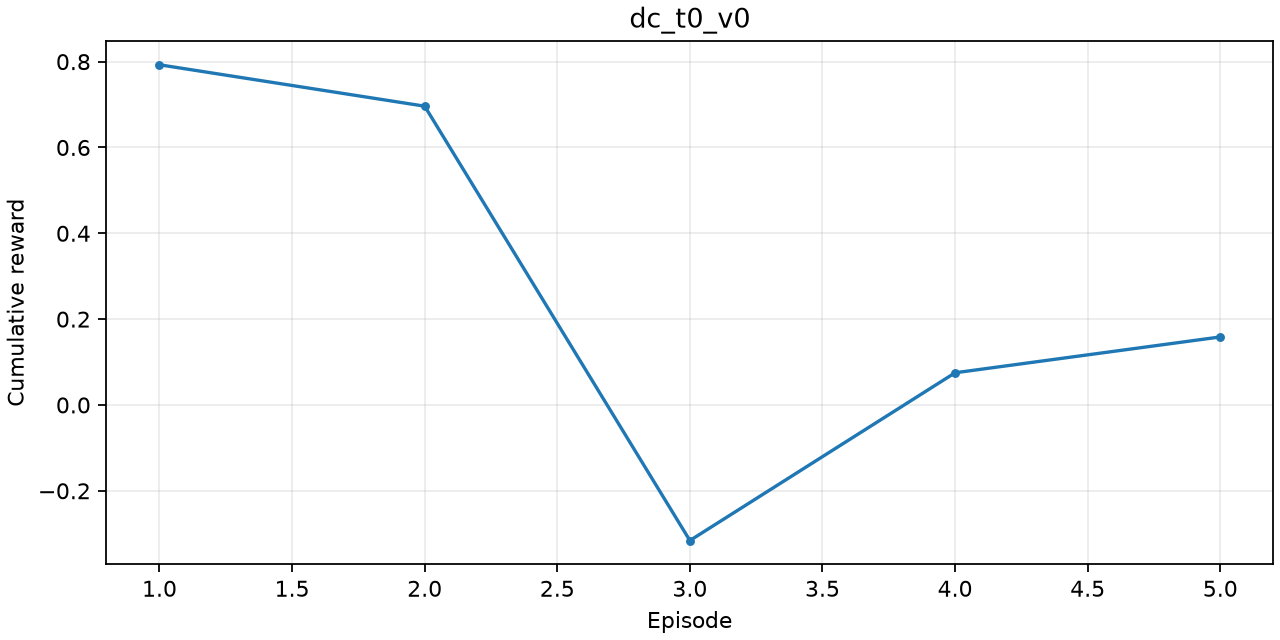

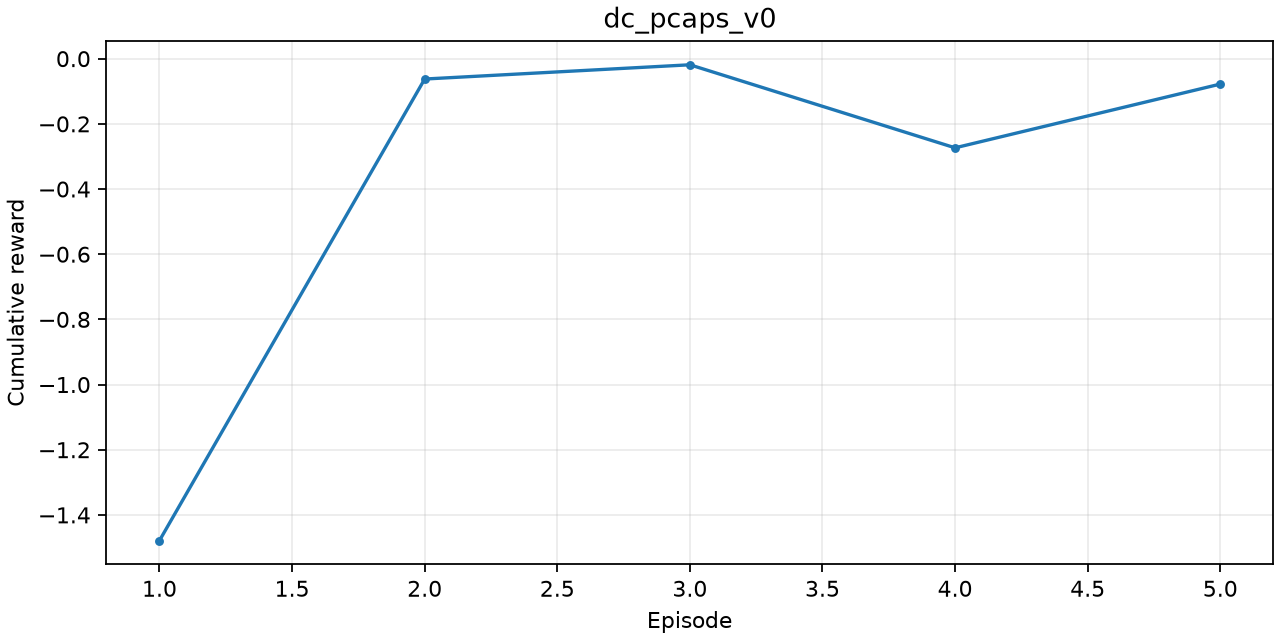

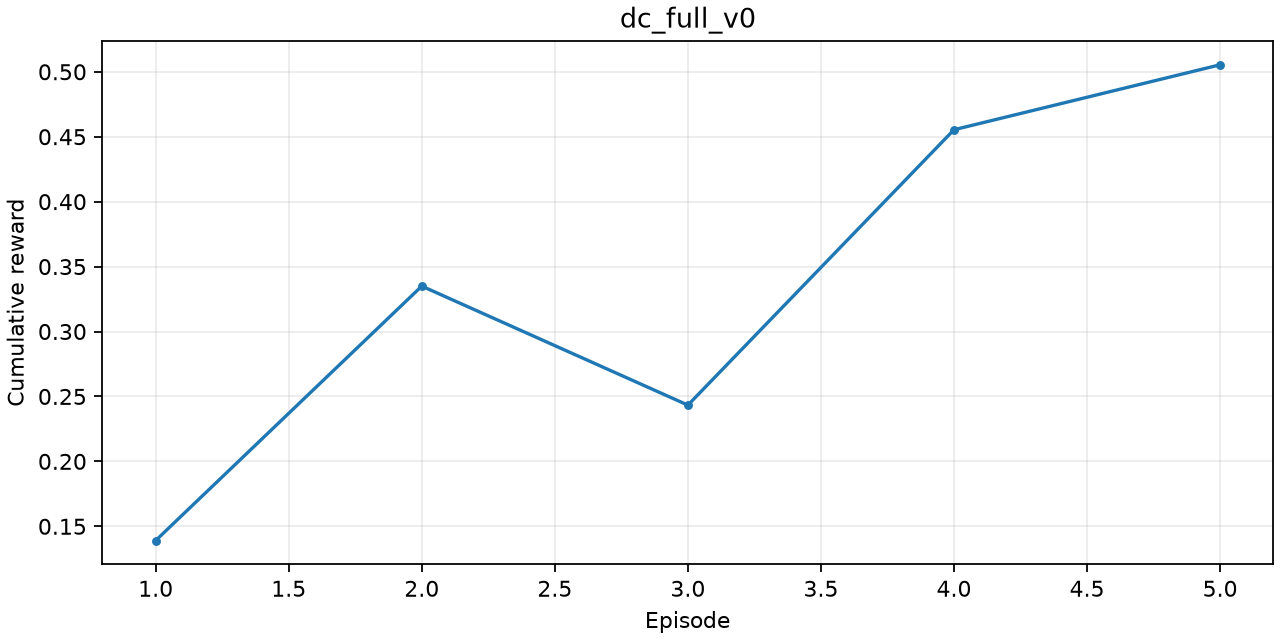

In [27]:
run(
    "model.eval_topology_embeddings",
    "--network",
    f"{CURRENT_TOPOLOGY}.json",
    "--model",
    MODELS[0],
    "--seed",
    SEED,
)
run(
    "model.eval_topologies",
    "--network",
    f"{CURRENT_TOPOLOGY}.json",
    "--models",
    *MODELS,
    "--episodes",
    EVAL_EPISODES,
    "--repetitions",
    REPETITIONS,
    "--seed",
    SEED,
)
for label in ("dc_t0", "dc_pcaps", "dc_full"):
    show_png(f"eval/{label}_{CURRENT_TOPOLOGY}.png")

## Inspect aggregate topology figures

After collecting all five topologies, these commands redraw the topology figures from saved measurements. The topology scatter contains 80 points in five classes. Each metric chart has five topology groups and three model bars per group.


Collected ['v0', 'v1', 'v2', 'v3']
/home/olzhas/sdn/EAGLE-replica/model/.venv/bin/python -m model.eval_topology_embeddings --model dc_t0 --seed 42 --plot-only
/home/olzhas/sdn/EAGLE-replica/model/.venv/bin/python -m model.eval_topologies --models dc_t0 dc_pcaps dc_full --plot-only


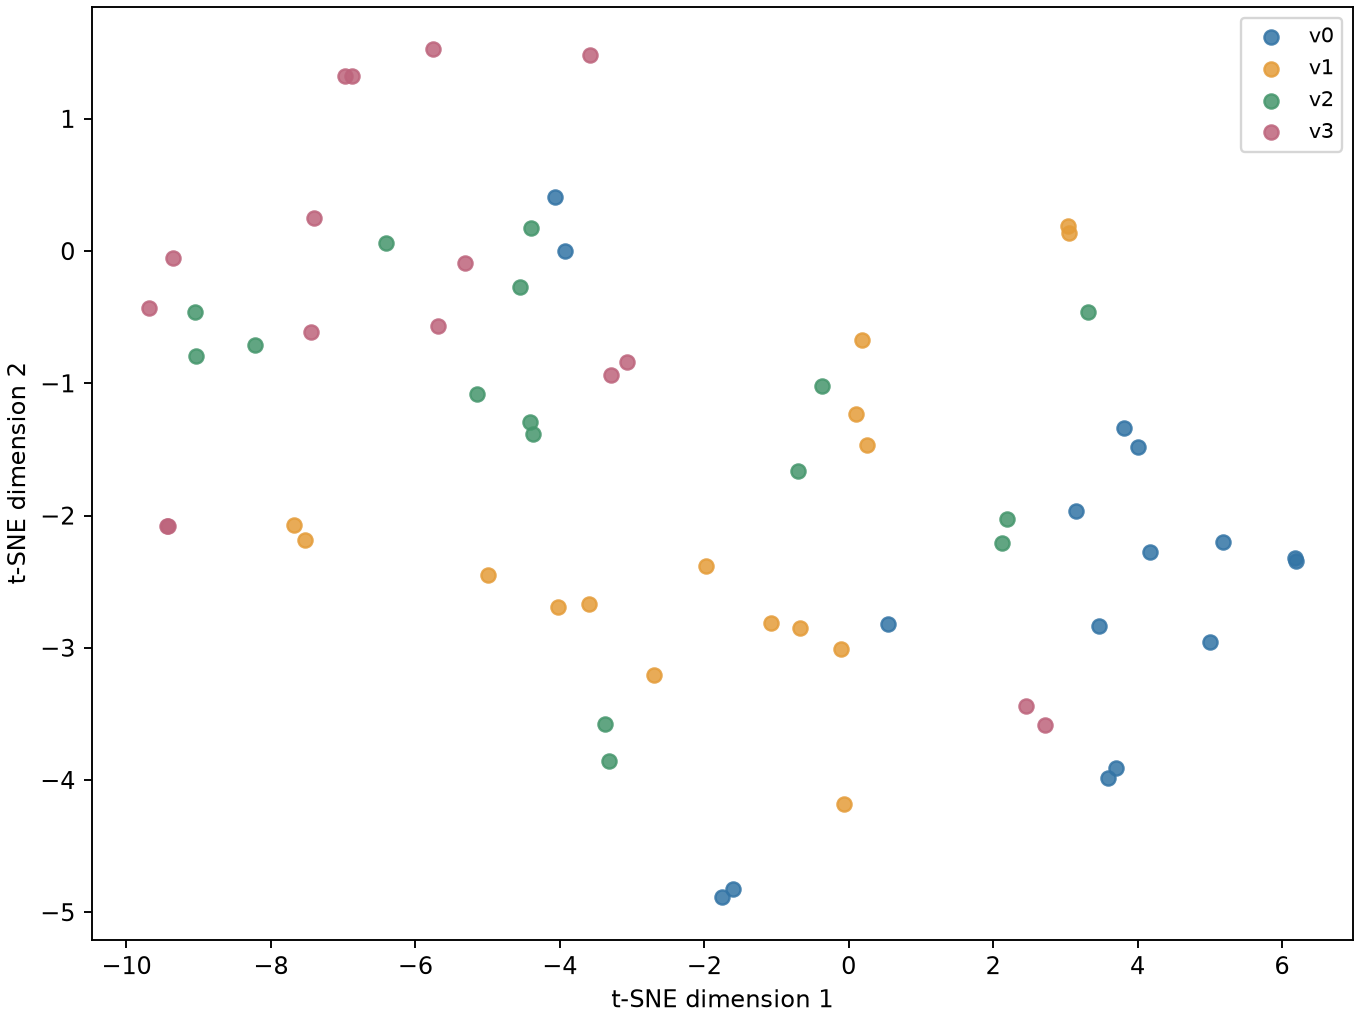

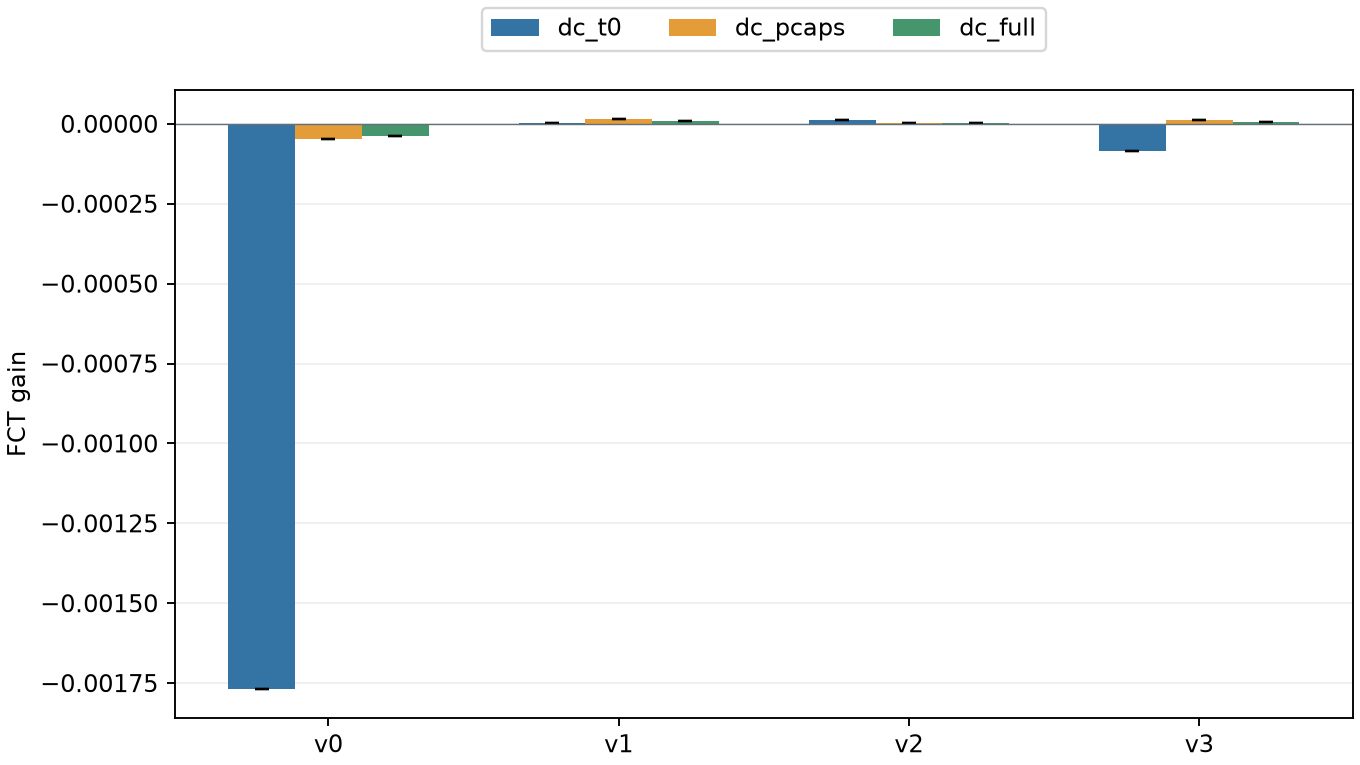

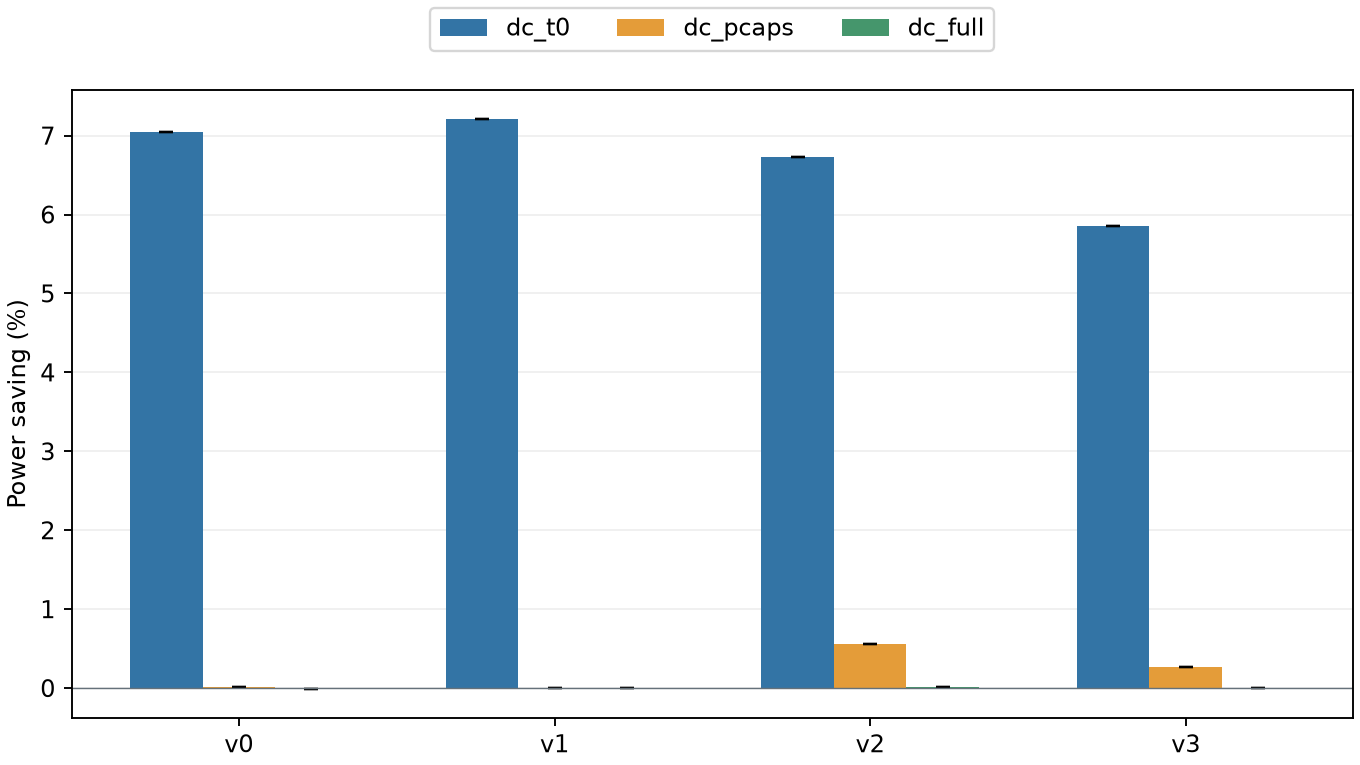

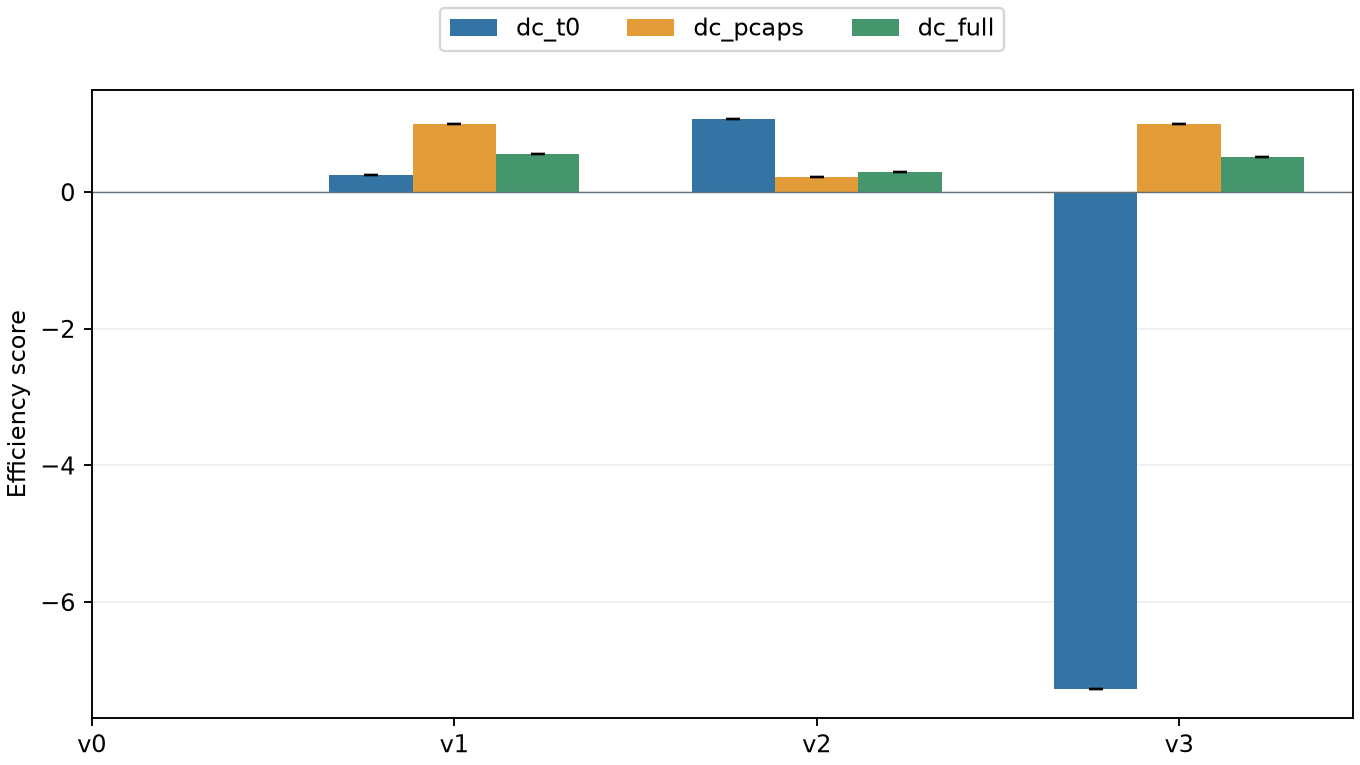

In [28]:
collected = [
    topology
    for topology in (f"v{i}" for i in range(4))
    if (ROOT / f"eval/topologies_{topology}.json").exists()
    and (ROOT / f"eval/topology_embeddings_{topology}.json").exists()
]
print("Collected", collected)
if len(collected) == 4:
    run(
        "model.eval_topology_embeddings",
        "--model",
        MODELS[0],
        "--seed",
        SEED,
        "--plot-only",
    )
    run("model.eval_topologies", "--models", *MODELS, "--plot-only")
    show_png("eval/topology_embeddings.png")
    for metric in ("fct_gain", "power_saving", "efficiency"):
        show_png(f"eval/topologies_{metric}.png")

## Evaluation 5 — pruning reward comparison

Compare cumulative reward over episodes and percentage change relative to the no-pruning run. Curves align by episode number. Relative values use the absolute no-pruning reward as the denominator.


/home/olzhas/sdn/EAGLE-replica/model/.venv/bin/python -m model.eval_pruning


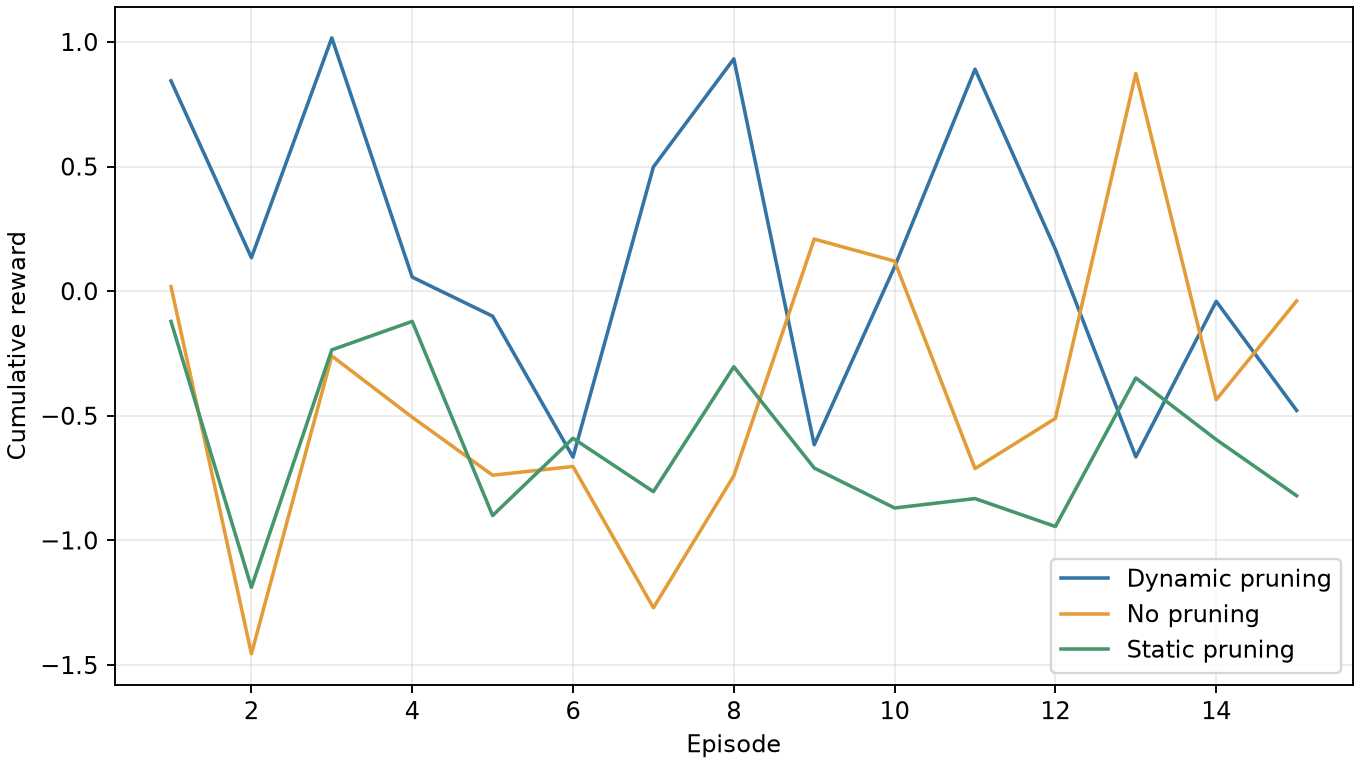

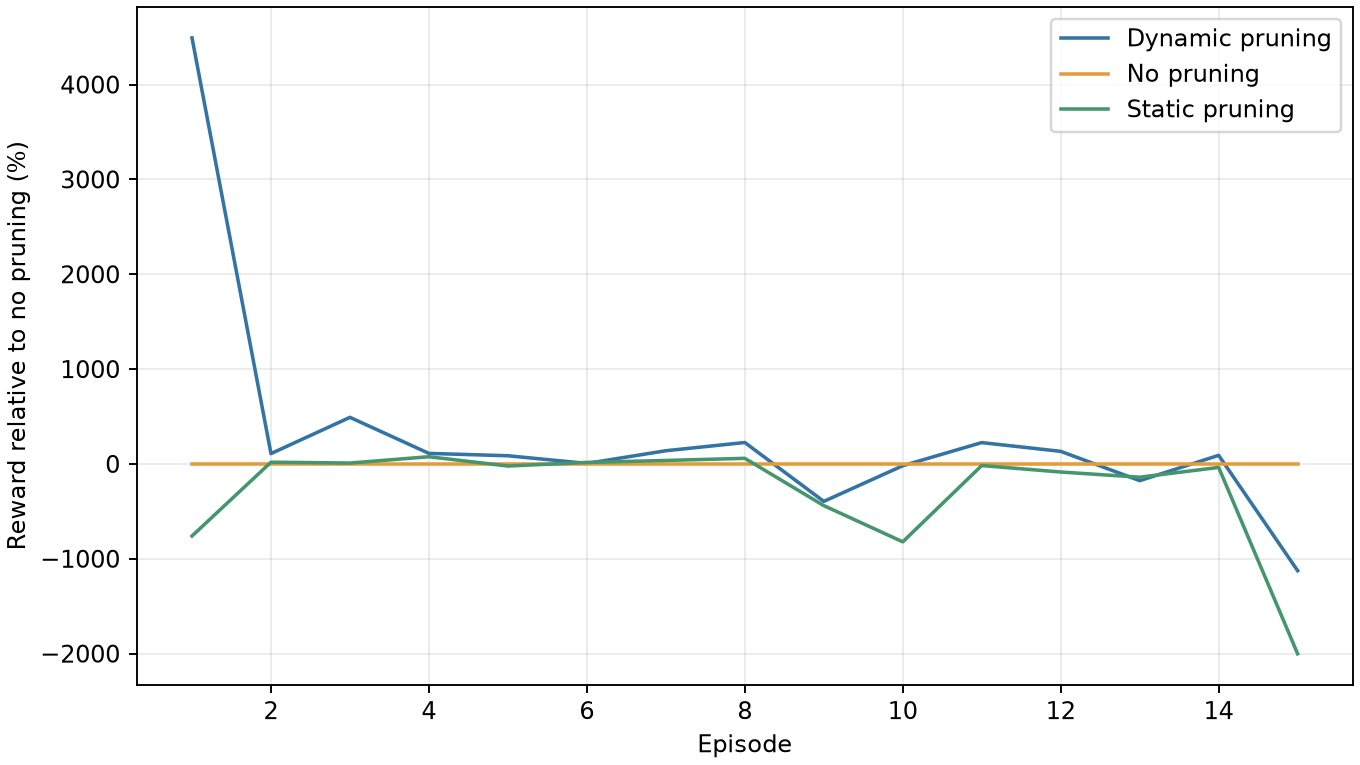

In [5]:
run("model.eval_pruning")
show_png("eval/pruning_reward.png")
show_png("eval/pruning_relative.png")

## Inspect saved data

Training returns live beside each inference model. Evaluation 4 saves three reward CSVs per topology under `eval/`. JSON reports retain repetition seeds and raw FCT and power measurements. The drain period is configurable in `settings/default.json`. Incomplete deliveries are ignored afterwards.


In [29]:
import csv

with (ROOT / "models/dc_t0.csv").open() as stream:
    rows = list(csv.DictReader(stream))
print("First training episodes", rows[:5])

report = json.loads((ROOT / "eval/datasets.json").read_text())
print("Compared models", report["models"])
print("Evaluated datasets", [row["dataset"] for row in report["conditions"]])

First training episodes [{'episode': '1', 'cumulative_reward': '0.8440204742364585'}, {'episode': '2', 'cumulative_reward': '0.1344779464416206'}, {'episode': '3', 'cumulative_reward': '1.0163552698213607'}, {'episode': '4', 'cumulative_reward': '0.05649190163239837'}, {'episode': '5', 'cumulative_reward': '-0.10022652929183096'}]
Compared models ['dc_t0_t5', 'dc_pcaps_t5', 'dc_full_t5']
Evaluated datasets ['dc_t0', 'mg_t0', 'dc_t1', 'dc_t3', 'dc_t4', 'dc_t0_trenv2', 'dc_t0_trenv3', 'dc_t0_trenv4', 'dc_t0_trenv5']
